# omics_and_virulence — the genome, RNA-seq and infection-assay panels

Run top to bottom from this folder (`jupyter nbconvert --to notebook --execute --inplace
omics_and_virulence.ipynb`, ~4 min). Every panel is written on its own to `outputs/`, as PDF
and as PNG/SVG preview. How panels are composed into the figures of the manuscript is a
presentation choice and is not part of this repository.


Figure 3: **A** heterozygous allele-frequency histogram (triploid signature, peaks at 0.33/0.66);
**B** gene copy number by effector family, from the unfiltered `gene_ploidy_v2.csv` calls
(Knaus et al. 2020 method); **C** WGS read depth over AVR1, AVR3b, AVR4 and AVR3a;
**D** curated panel of named AVR/effector genes as mean log2(TPM + 1), rows clustered
(PITG_15278 and AVR-cap1b are not shown; AVR-smira2 is labeled AVR8). Genes tested in the
potato or *N. benthamiana* assays are marked with an asterisk and bold text.

Figure 4: **A** potato leaf infection assay (Spunta / Innovator); **B** map of the Argentine
isolates and their phenotype on Innovator (`../SSR_populations/outputs/s2/mapa_argentina_innovator.png`,
from `haplotype_network_v4.R`, so that script must have been run first); **C** AVR1/AVR2/AVR3a/AVR3b
mean log2(TPM + 1).

The panels, by section: the triploid allele-frequency histogram, gene copy number by effector
family, the curated effector panel, the volcano plots and expression modes, the mapping-quality
comparison, the WGS coverage profiles over AVR1/AVR3b/AVR4/AVR3a, the AVR1/AVR2/AVR3a/AVR3b and
AVR1/AVR3a/AVR-blb2/AVR-amr1/AVR-amr3 TPM plots, and the two detached-leaf assays (potato
cultivars and transgenic *N. benthamiana*). The AVR-blb2 paralog family is its own analysis in
`avrblb2_family/`.

In [1]:
# -- Output folders (created once; each section writes into its own subfolder) --
import os

for _d in ["../Figures", "outputs/fig3", "outputs/fig_sup3", "outputs/fig_sup4", "outputs/fig4", "outputs/fig5"]:
    os.makedirs(_d, exist_ok=True)


def place_panel_letters(fig, panels, rows=(), cols=(), size=20, pad=0.004):
    """Draws the panel letters so that letters in the same row share one baseline and
    letters in the same column share one x. `panels` maps letter -> list of axes; each
    letter goes at the top-left corner of the union of its axes' tight bounding boxes
    (tick labels, axis labels and titles included)."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    to_fig = fig.transFigure.inverted()
    box = {}
    for L, axes in panels.items():
        bbs = [ax.get_tightbbox(renderer).transformed(to_fig) for ax in axes]
        box[L] = (min(b.x0 for b in bbs), max(b.y1 for b in bbs))
    x = {L: b[0] for L, b in box.items()}
    y = {L: b[1] for L, b in box.items()}
    for col in cols:
        for L in col:
            x[L] = min(box[M][0] for M in col)
    for row in rows:
        for L in row:
            y[L] = max(box[M][1] for M in row)
    for L in panels:
        fig.text(x[L], y[L] + pad, L, fontsize=size, fontweight="bold", ha="left", va="bottom")


## Panel A — Heterozygous allele frequency distribution (ploidy evidence)

Analysis of **nQuire** (`lrdmodel`) output. `PiNSL19_freqs.txt` has three tab-separated
columns (no header): total read depth, minor allele count (**b**), major allele count (**a**).
For a **triploid** sample, heterozygous sites show a bimodal distribution: allele **b** (minor)
peaks near **0.33**, allele **a** (major) peaks near **0.66**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt


In [3]:
# ── Settings ──────────────────────────────────────────────────────────────────
FILEPATH_A     = "inputs/PiNSL19_freqs.txt"             # path to nQuire freqs file
OUTPUT_A       = "outputs/fig3/PiNSL19_allele_freqs_vertical.png"
DPI_A          = 600

N_COLORS       = 20    # viridis ramp sampled at 20 points; indices below pick two swatches
COLOR_IDX_B    = 4     # allele b (minor,  ~0.33)
COLOR_IDX_A    = 14    # allele a (major,  ~0.66)
ALPHA_A        = 0.88

N_BINS         = 50    # histogram bins between 0 and 1

REF_COLOR      = "#c0392b"   # dashed reference lines at 1/3, 2/3
REF_LINEWIDTH  = 1.7

viridis = matplotlib.colormaps["inferno"]
ramp    = [viridis(i / (N_COLORS - 1)) for i in range(N_COLORS)]


In [4]:
# ── Load data ─────────────────────────────────────────────────
df_a = pd.read_csv(FILEPATH_A, sep="\t", header=None, names=["total", "minor", "major"])
print(f"Sites loaded : {len(df_a):,}")
df_a.head()


Sites loaded : 1,122,655


,total,minor,major
0,20,7,13
1,24,6,18
2,24,6,18
3,25,6,19
4,35,10,25


In [5]:
# ── Compute frequencies ───────────────────────────────────────────────────────
df_a["freq_b"] = df_a["minor"] / df_a["total"]   # minor allele b  ->  ~0.33
df_a["freq_a"] = df_a["major"] / df_a["total"]   # major allele a  ->  ~0.66

# Keep only sites where both alleles are present
df_a = df_a[(df_a["freq_b"] > 0) & (df_a["freq_a"] < 1)]

print(f"Sites after filter : {len(df_a):,}")
print(f"Mean freq_b (minor allele) : {df_a['freq_b'].mean():.4f}")
print(f"Mean freq_a (major allele) : {df_a['freq_a'].mean():.4f}")


Sites after filter : 1,122,655
Mean freq_b (minor allele) : 0.3212
Mean freq_a (major allele) : 0.6766


In [6]:
# ── Bins, colors, reference ticks ────────────────────────────────────────────
bins    = np.linspace(0, 1, N_BINS + 1)
color_b = ramp[COLOR_IDX_B]
color_a = ramp[COLOR_IDX_A]

std_ticks = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
ref_ticks = [1/3, 2/3]
all_ticks = sorted(std_ticks + ref_ticks)

tick_labels = []
for t in all_ticks:
    if abs(t - 1/3) < 1e-9:
        tick_labels.append("0.33")
    elif abs(t - 2/3) < 1e-9:
        tick_labels.append("0.66")
    else:
        tick_labels.append(f"{t:.1f}")


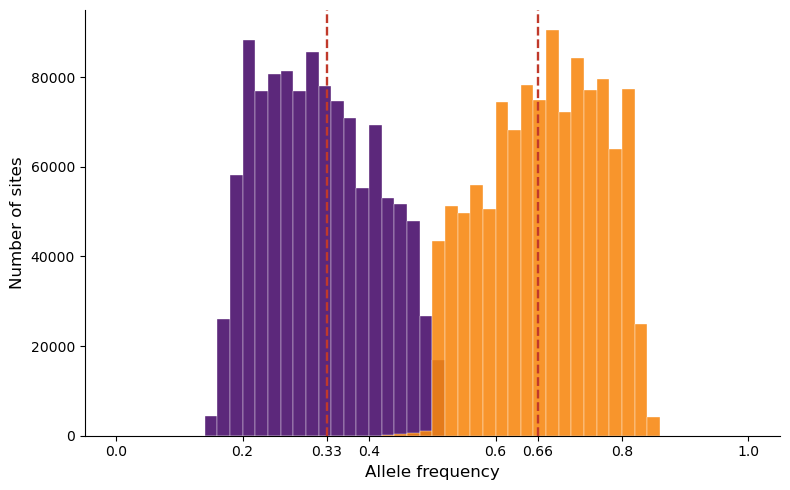

Figure saved as outputs/fig3/PiNSL19_allele_freqs_vertical.png


In [7]:
# ── Bimodal histogram, horizontal format (X = Allele frequency, Y = Number of sites) ──
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(df_a["freq_b"], bins=bins, color=color_b, alpha=ALPHA_A,
        edgecolor="white", linewidth=0.3)
ax.hist(df_a["freq_a"], bins=bins, color=color_a, alpha=ALPHA_A,
        edgecolor="white", linewidth=0.3)

for xpos in [1/3, 2/3]:
    ax.axvline(x=xpos, color=REF_COLOR, linestyle="--", linewidth=REF_LINEWIDTH, zorder=5)

ax.set_xticks(all_ticks)
ax.set_xticklabels(tick_labels)

ax.set_xlabel("Allele frequency", fontsize=12)
ax.set_ylabel("Number of sites", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(OUTPUT_A, dpi=DPI_A, bbox_inches="tight", format="png")
plt.show()
print(f"Figure saved as {OUTPUT_A}")

## Gene copy number per effector family, unfiltered (Figure 3, panel B)

Reads `gene_ploidy_v2.csv` (columns: `gene`, `allele`, `class`, `type`) and plots the
proportion of genes per copy-number category (`allele`: 2, 3, 4, >=5, NA) for each gene
family (`type`), plus an aggregate **total** bar, using every gene regardless of
mapping quality. This used to be assembled into the old, separate "CNV + volcano +
Venn" Supplementary Figure, alongside the volcano/Venn overlap analysis -- that figure
has since been retired (see the "Venn overlap data prep" section's own markdown
further below) -- and was later kept as a standalone diagnostic when Figure 3 was
simplified to a curated effector panel. It has since been revived as Figure 3's Panel
B, since Crinkler's copy-number skew visible here (about half at 2 copies, vs. ~12-18%
for the other families) is the entry point for the mapping-quality caveat discussed in
the Results text and detailed in Supplementary Figure S3. A mean-MAPQ > 30-filtered
version of this same breakdown was also tested as a candidate panel earlier in this
notebook's development but isn't part of any current figure -- see "Supplementary
Figure 3 (final layout)" further below for the mapping-quality evidence that motivated
testing that filter in the first place.

In [8]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


In [9]:
# ── Settings ──────────────────────────────────────────────────────────────────
FILEPATH_C = "inputs/gene_ploidy_v2.csv"
OUTPUT_C   = "outputs/fig_sup4/gene_ploidy_barplot.png"  # moved out of fig3/ -- see markdown above
DPI_C      = 600

BAR_ORDER = [
    ("RxLR",       "RxLR"),
    ("CRN",        "Crinkler"),
    ("apoplastic", "apoplastic"),
    ("ubiquitin",  "ubiquitin"),
    ("total",      "total"),
]

ALLELE_ORDER  = ["NA", "2", "3", "4", "5"]
ALLELE_LABELS = {"NA": "NA", "2": "2", "3": "3", "4": "4", "5": ">=5"}

N_COLORS_C = 20
COLOR_IDX_C = {
    "NA": None,   # None -> GRAY_COLOR
    "2":  3,
    "3":  11,
    "4":  15,
    "5":  19,
}
GRAY_COLOR = "#888888"
ALPHA_C    = 0.92

BAR_WIDTH  = 1.0
FIG_WIDTH  = 6.5
FIG_HEIGHT = 5.5

viridis_c = matplotlib.colormaps["inferno"]
ramp_c    = [viridis_c(i / (N_COLORS_C - 1)) for i in range(N_COLORS_C)]


In [10]:
# ── Load & tidy data ──────────────────────────────────────────────────────────
df_c = pd.read_csv(FILEPATH_C)
print(f"Rows loaded: {len(df_c):,}")

def allele_label(val):
    if pd.isna(val):
        return "NA"
    v = int(val)
    return "5" if v >= 5 else str(v)

df_c["allele_cat"] = df_c["allele"].apply(allele_label)

# Add a 'total' pseudo-type
df_c_total = df_c.copy()
df_c_total["type"] = "total"
df_c_all = pd.concat([df_c, df_c_total], ignore_index=True)

df_c_all.head()


Rows loaded: 18,179


,gene,allele,class,type,allele_cat
0,PITG_00002,2.0,other,other,2
1,PITG_00003,2.0,other,other,2
2,PITG_00004,2.0,other,other,2
3,PITG_00005,2.0,other,other,2
4,PITG_00006,2.0,other,other,2


In [11]:
# ── Compute proportions ───────────────────────────────────────────────────────
counts_c = (
    df_c_all.groupby(["type", "allele_cat"], observed=True)
    .size()
    .unstack(fill_value=0)
)

for cat in ALLELE_ORDER:
    if cat not in counts_c.columns:
        counts_c[cat] = 0

props_c = counts_c.div(counts_c.sum(axis=1), axis=0) * 100   # proportions in %
print(props_c.round(1))


allele_cat     2     3     4    5   NA
type                                  
CRN         49.2  34.4  10.2  4.7  1.6
RxLR        13.5  72.2   9.3  0.5  4.5
apoplastic  11.6  73.9  10.9  1.7  2.0
other        7.9  77.5   9.4  1.2  4.0
total        8.4  77.0   9.4  1.2  3.9
ubiquitin    4.1  76.5  13.3  1.0  5.1


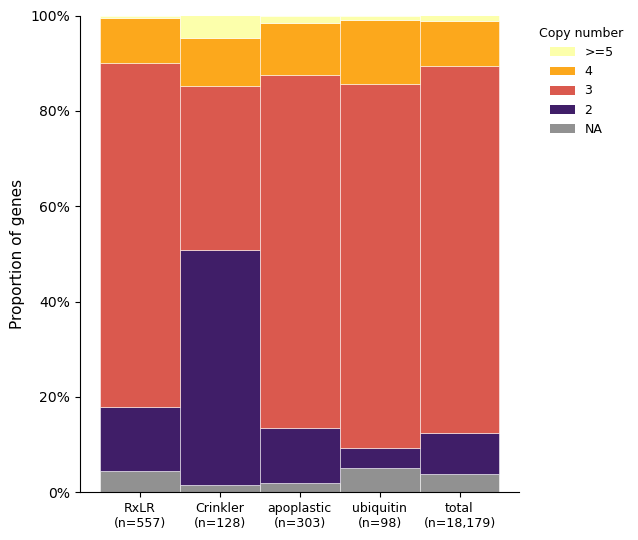

Figure saved as outputs/fig_sup4/gene_ploidy_barplot.png


In [12]:
# ── Stacked bar chart ─────────────────────────────────────────────────────────
palette_c = {}
for cat, idx in COLOR_IDX_C.items():
    palette_c[cat] = GRAY_COLOR if idx is None else ramp_c[idx]

types_c, xlabels_c = zip(*BAR_ORDER)
n_bars = len(types_c)

n_total_all = len(df_c)
size_map = dict(df_c["type"].value_counts())
size_map["total"] = n_total_all

tick_labels_c = []
for typ, lbl in BAR_ORDER:
    n = size_map.get(typ, 0)
    tick_labels_c.append(f"{lbl}\n(n={n:,})")

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

x = np.arange(n_bars)
bottoms = np.zeros(n_bars)

for cat in ALLELE_ORDER:
    heights = np.array([props_c.loc[t, cat] if t in props_c.index else 0.0 for t in types_c])
    ax.bar(
        x, heights, bottom=bottoms,
        width=BAR_WIDTH,
        color=palette_c[cat],
        alpha=ALPHA_C,
        edgecolor="white",
        linewidth=0.4,
        label=ALLELE_LABELS[cat],
    )
    bottoms += heights

ax.set_xticks(x)
ax.set_xticklabels(tick_labels_c, fontsize=9)
ax.set_ylabel("Proportion of genes", fontsize=11)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter())
ax.spines[["top", "right"]].set_visible(False)

handles = [
    mpatches.Patch(facecolor=palette_c[cat], alpha=ALPHA_C, label=ALLELE_LABELS[cat])
    for cat in reversed(ALLELE_ORDER)
]
ax.legend(
    handles=handles, title="Copy number", title_fontsize=9, fontsize=9,
    frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1),
)

plt.tight_layout()
plt.savefig(OUTPUT_C, dpi=DPI_C, bbox_inches="tight", format="png")
plt.show()
print(f"Figure saved as {OUTPUT_C}")


## Curated effector panel — resistance-relevant AVR/effector genes (Figure 3, panel C)

Earlier versions of this section built a genome-wide heatmap of every effector
significantly induced during infection (up to 160 genes at the |log2FC| > 2 / adjusted
p < 0.05 threshold used elsewhere in the manuscript) -- exhaustive, but too large for
any single gene to stand out, and built on a differential-expression criterion that
silently drops genes genuinely transcribed in planta without being "induced" relative
to axenic mycelium. *AVR-amr1* is the clearest case: its TPM is comparable in mycelium
and during infection (no significant log2FC at any timepoint, all p > 0.1), yet
*Rpi-amr1* confers real resistance in the *N. benthamiana* assay below -- recognition
only requires the effector to be present during infection, not upregulated relative to
an arbitrary baseline.

This section replaces that heatmap with a curated panel of 27 named RXLR effectors
with known or candidate relevance to potato late-blight resistance breeding: every
named-AVR RXLR gene in `tabla_efectores.xlsx` (AVR1, AVR2 x2 loci, AVR3a, AVR3b, AVR4,
AVR10, AVR-amr1, AVR-amr3, AVR-amr4, AVR-amr16, AVR-amr17, AVR-blb1,
AVR-smira1, AVR-smira2 (shown as AVR8, the effector recognized by R8 = Rpi-smira2), AVR-vnt1;
PITG_15278 and AVR-cap1b are not shown) plus the AVR-blb2 paralog family,
expanded from the single PITG_20300 representative used in Figure 4/5's TPM line plots
to include every paralog shown expressed in Figure 5's circular tree (PITG_04085,
PITG_04086, PITG_04090, PITG_18670, PITG_18685, PITG_22604) plus PITG_20301 and
PITG_20303 specifically.

Shown as mean log2(TPM + 1) (not log2FC) across in vitro mycelium and 24/48/72 hpi,
pulled directly from the genome-wide `TPM_matrix.tsv` so every gene sits on the same
absolute scale regardless of whether it passes any differential-expression filter.
Genes also evaluated experimentally later in the manuscript (Figure 4's potato assay
and coverage panels, Figure 5's *N. benthamiana* assay) are marked with an asterisk and
bold row labels. Rows are grouped by gene family (alphabetical, so AVR-blb2's nine
paralogs sit together) rather than clustered, since the point of this panel is to look
up a specific named gene, not to explore unsupervised structure.

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# ── Config: the 27-gene curated panel ──────────────────────────────────────────
# Every RXLR-category row from tabla_efectores.xlsx's named-AVR set, plus the
# AVR-blb2 family expanded per the markdown above (replacing the single PITG_20300
# used as "the" AVR-blb2 representative in Figure 4/5's TPM line plots).
CURATED_GENES = [
    ("PITG_16663", "AVR1"),
    ("PITG_08943", "AVR2"),
    ("PITG_22870", "AVR2"),
    ("PITG_14371", "AVR3a"),
    ("PITG_18215", "AVR3b"),
    ("PITG_07387", "AVR4"),
    ("PITG_11484", "AVR10"),
    ("PITG_07569", "AVR-amr1"),
    ("PITG_21190", "AVR-amr3"),
    ("PITG_22825", "AVR-amr4"),
    ("PITG_02860", "AVR-amr16"),
    ("PITG_04373", "AVR-amr17"),
    ("PITG_21388", "AVR-blb1"),
    ("PITG_04085", "AVR-blb2 fam."),
    ("PITG_04086", "AVR-blb2 fam."),
    ("PITG_04090", "AVR-blb2 fam."),
    ("PITG_20300", "AVR-blb2 fam."),
    ("PITG_07550", "AVR-smira1"),
    ("PITG_07558", "AVR8 (AVR-smira2)"),  # Rpi-smira2 = R8
    ("PITG_16294", "AVR-vnt1"),
]

# Genes also evaluated experimentally in Figure 4 (potato assay + coverage) or
# Figure 5 (N. benthamiana assay) -- marked with an asterisk and bold below.
TESTED_DOWNSTREAM = {
    "PITG_16663",                # AVR1 -- Figure 4
    "PITG_08943", "PITG_22870",  # AVR2, both loci -- Figure 4
    "PITG_14371",                # AVR3a -- Figure 4 & 5
    "PITG_18215",                # AVR3b -- Figure 4
    "PITG_04090",                # AVR-blb2, Figure 5's representative paralog
    "PITG_07569",                # AVR-amr1 -- Figure 5
    "PITG_21190",                # AVR-amr3 -- Figure 5
}

TIME_ORDER = ["Myc", "24", "48", "72"]

def parse_tpm_matrix_col(col):
    """TPM_matrix.tsv column -> timepoint label. Same convention as parse_col_5 in
    the Figure 5 TPM section: 'B3' = Experiment B, 24 hpi; 'Ctrl*' = mycelium."""
    if col.startswith("Ctrl"):
        return "Myc"
    return {"3": "24", "4": "48", "5": "72"}[col[1]]

In [14]:
# ── Load genome-wide TPM matrix and compute mean log2(TPM + 1) per gene x timepoint ──
TPM_MATRIX_PATH = "inputs/TPM_matrix.tsv"

tmat = pd.read_csv(TPM_MATRIX_PATH, sep="\t")
curated_ids = [gid for gid, _ in CURATED_GENES]
missing = set(curated_ids) - set(tmat["gene_id"])
if missing:
    print(f"WARNING: {len(missing)} curated gene(s) not found in {TPM_MATRIX_PATH}: {sorted(missing)}")

sub_tmat = tmat[tmat["gene_id"].isin(curated_ids)].set_index("gene_id")
col_time = {c: parse_tpm_matrix_col(c) for c in tmat.columns[1:]}

rows = []
for gid, gname in CURATED_GENES:
    r = sub_tmat.loc[gid]
    for t in TIME_ORDER:
        cols_t = [c for c, tt in col_time.items() if tt == t]
        rows.append({"Gene_ID": gid, "gene_name": gname, "Time": t,
                     "mean_TPM": r[cols_t].astype(float).values.mean()})

curated_long = pd.DataFrame(rows)
curated_long["log2TPM1"] = np.log2(curated_long["mean_TPM"] + 1)

curated_heat = curated_long.pivot(index="Gene_ID", columns="Time", values="log2TPM1")[TIME_ORDER]
curated_heat = curated_heat.loc[curated_ids]   # CURATED_GENES order, before clustering

# Row labels WITHOUT the PITG id (just the gene/family name), asterisk + bold
# still marking genes also evaluated experimentally in Figure 4/5.
curated_labels = [
    f"{gname}{'*' if gid in TESTED_DOWNSTREAM else ''}"
    for gid, gname in CURATED_GENES
]

print(curated_heat.round(1))


# ── Hierarchical clustering of the 27 rows (average linkage, Euclidean distance ──
# ── on the log2(TPM+1) profile) -- dependency-free, since scipy isn't available  ──
# ── in this environment (same constraint as the AVR-blb2 NJ tree earlier in this ──
# ── notebook). Clusters on absolute expression level *and* shape together (raw   ──
# ── log2(TPM+1), not z-scored), which is what separates "always off" genes like  ──
# ── AVR1/AVR3b from strongly time-varying ones like AVR2/AVR-blb2.               ──
def hclust_average(X):
    """Returns a linkage list [(a, b, height, size), ...] in merge order, using
    leaf indices 0..n-1 and internal-node indices n, n+1, ... -- same convention
    as scipy's linkage matrix, just without scipy."""
    n = X.shape[0]
    dist = {}
    for i in range(n):
        for j in range(i + 1, n):
            dist[(i, j)] = float(np.linalg.norm(X[i] - X[j]))
    size = {i: 1 for i in range(n)}
    active = list(range(n))
    next_id = n
    Z = []
    def get(a, b):
        return dist[(a, b)] if a < b else dist[(b, a)]
    while len(active) > 1:
        best = None
        for ii in range(len(active)):
            for jj in range(ii + 1, len(active)):
                a, b = active[ii], active[jj]
                dd = get(a, b)
                if best is None or dd < best[0]:
                    best = (dd, a, b)
        dd, a, b = best
        new_id = next_id; next_id += 1
        na, nb = size[a], size[b]
        for c in active:
            if c in (a, b):
                continue
            new_d = (na * get(a, c) + nb * get(b, c)) / (na + nb)
            dist[(min(new_id, c), max(new_id, c))] = new_d
        size[new_id] = na + nb
        Z.append((a, b, dd, na + nb))
        active = [c for c in active if c not in (a, b)] + [new_id]
    return Z

def dendrogram_layout(Z, n):
    """Leaf order (left-to-right) and (x, height) for every node, classic
    dendrogram convention."""
    children, heights = {}, {i: 0.0 for i in range(n)}
    for k, (a, b, h, _) in enumerate(Z):
        children[n + k] = (a, b)
        heights[n + k] = h
    leaf_order = []
    def collect(node):
        if node < n:
            leaf_order.append(node)
        else:
            a, b = children[node]
            collect(a); collect(b)
    root = n + len(Z) - 1
    collect(root)
    x_of = {leaf: rank for rank, leaf in enumerate(leaf_order)}
    def compute_x(node):
        if node < n:
            return x_of[node]
        a, b = children[node]
        x_of[node] = (compute_x(a) + compute_x(b)) / 2.0
        return x_of[node]
    compute_x(root)
    return leaf_order, x_of, heights, children, root

curated_Z = hclust_average(curated_heat.values)
curated_leaf_order, curated_x_of, curated_heights, curated_children, curated_root = \
    dendrogram_layout(curated_Z, len(curated_ids))

# Re-order everything by the dendrogram's leaf order for plotting.
curated_heat_ordered = curated_heat.iloc[curated_leaf_order]
curated_labels_ordered = [curated_labels[i] for i in curated_leaf_order]
curated_tested_ordered = [curated_ids[i] in TESTED_DOWNSTREAM for i in curated_leaf_order]
# x-position of each leaf/internal node in the reordered (0..n-1 rank) coordinate
# frame -- leaves already are their own rank; internal-node x's from curated_x_of
# are already expressed in that same rank space (computed from leaf_order above).

Time        Myc    24    48    72
Gene_ID                          
PITG_16663  0.0   0.0   0.0   0.0
PITG_08943  0.7  10.1  10.3   9.2
PITG_22870  0.6   9.7  10.3   9.0
PITG_14371  3.7  10.0  10.6  10.1
PITG_18215  0.0   0.0   0.0   0.0
PITG_07387  0.1   0.0   2.9   1.5
PITG_11484  0.7  10.4   9.3   7.3
PITG_07569  4.6   0.0   6.0   5.6
PITG_21190  0.9   5.1   4.0   2.7
PITG_22825  0.8   6.9   5.9   3.9
PITG_02860  1.1   5.6   7.9   8.3
PITG_04373  2.6   0.0   4.5   3.0
PITG_21388  5.4  10.3   9.2   7.0
PITG_04085  0.2   7.6  11.2  10.4
PITG_04086  0.2   7.6  11.0  10.3
PITG_04090  1.7   9.2  11.4  10.9
PITG_20300  0.6   6.5  10.4   9.9
PITG_07550  2.8   8.7   7.0   4.7
PITG_07558  1.1   0.0   1.8   1.5
PITG_16294  2.0   9.1   8.8   7.3


C:\Users\Marce\AppData\Local\Temp\ipykernel_10376\3239224622.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


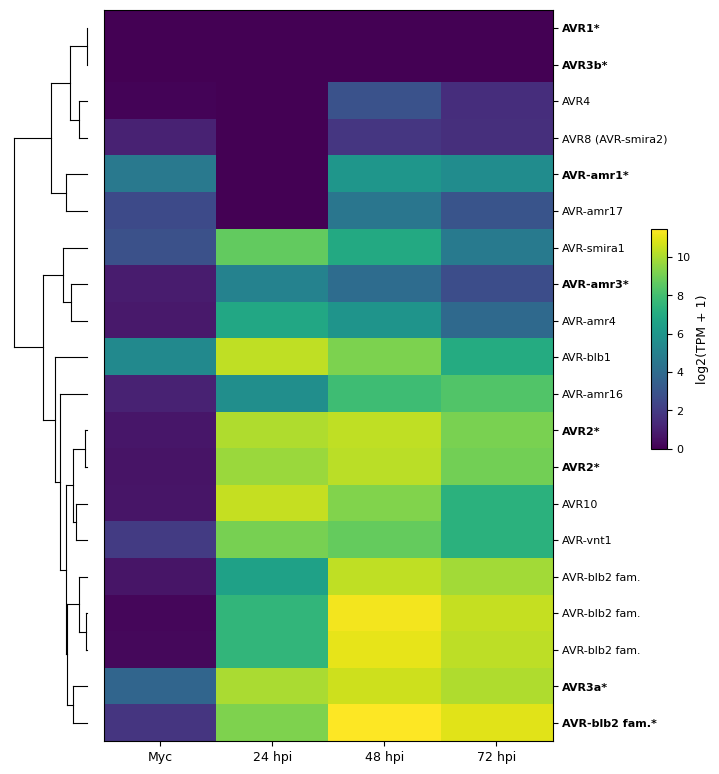

In [15]:
# ── Standalone render of the curated panel (also embedded in Figure 3's final layout) ──
fig = plt.figure(figsize=(7, 9.5))
gs = fig.add_gridspec(1, 2, width_ratios=[0.18, 1], wspace=0.05)
ax_dendro = fig.add_subplot(gs[0])
ax_heat = fig.add_subplot(gs[1])

n_curated = len(curated_ids)
for k, (a, b, h, _) in enumerate(curated_Z):
    node_id = n_curated + k
    xa, xb = curated_x_of[a], curated_x_of[b]
    ha, hb = curated_heights[a], curated_heights[b]
    ax_dendro.plot([ha, h], [xa, xa], color="black", linewidth=0.8)
    ax_dendro.plot([hb, h], [xb, xb], color="black", linewidth=0.8)
    ax_dendro.plot([h, h], [xa, xb], color="black", linewidth=0.8)
ax_dendro.set_ylim(-0.5, n_curated - 0.5)
ax_dendro.invert_yaxis()
ax_dendro.invert_xaxis()
ax_dendro.axis("off")

im = ax_heat.imshow(curated_heat_ordered.values, aspect="auto", cmap="viridis")
ax_heat.set_xticks(range(len(TIME_ORDER)))
ax_heat.set_xticklabels(["Myc", "24 hpi", "48 hpi", "72 hpi"], fontsize=9)
ax_heat.set_yticks(range(len(curated_labels_ordered)))
ax_heat.set_yticklabels(curated_labels_ordered, fontsize=8)
ax_heat.yaxis.tick_right()
for i, is_tested in enumerate(curated_tested_ordered):
    if is_tested:
        ax_heat.get_yticklabels()[i].set_fontweight("bold")

cbar_ax = ax_heat.inset_axes([1.22, 0.4, 0.035, 0.3])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("log2(TPM + 1)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.tight_layout()
os.makedirs("outputs/fig3", exist_ok=True)
plt.savefig("outputs/fig3/curated_effector_panel.png", dpi=300, bbox_inches="tight", pad_inches=0.3)
plt.show()

## Differential-expression data prep (feeds Supplementary Figure S3, panel A + the expression-mode clustering below)

Loads the full genome-wide DE table (`tabla_LFC_pvalor.tsv`, all 18,179 genes, not
just annotated effectors) and the effector classification table
(`tabla_efectores.xlsx`), and computes the per-timepoint upregulated-gene sets
(log2FC > 2, adjusted p-value < 0.05 vs. in vitro mycelium) used as a standalone
sanity check against the Results-text DE counts (153 genes upregulated at all three
timepoints, 81 of them annotated effectors). The DE table and category mapping loaded
here also feed the volcano plots directly below.

**Note:** this used to also feed a set of Venn diagrams (RxLR and Crinkler 3-way
overlaps by timepoint) in an earlier version of Supplementary Figure S3. Those added
little beyond what the per-timepoint counts already say and have been dropped -- the
volcano plots below show the same underlying DE result in a more informative form
(magnitude and significance per gene, not just a threshold pass/fail count).

In [16]:
# ── Config + load (self-contained: independent copies of the DE table and effector table) ──
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

LFC_TSV_PATH   = "inputs/tabla_LFC_pvalor.tsv"
EFFECTORS_XLSX = "inputs/tabla_efectores.xlsx"
LFC_THRESHOLD  = 2       # log2FC > 2 -- same cutoff used for the 496/153/81 counts reported in Results
PVAL_THRESHOLD = 0.05    # adjusted p-value < 0.05
TIME_LABELS    = {"T3": "24 hpi", "T4": "48 hpi", "T5": "72 hpi"}  # T1/T2 (in vitro mycelium) ignored, same as Panel C (the heatmap)

CATEGORY_COLORS = {
    "RXLR": "red",
    "CRINKLER": "blue",
    "APOPLASTIC": "gold",   # same color code as Figure 3F (the heatmap)
}

viridis = matplotlib.colormaps["viridis"]
TIMEPOINT_COLORS = {"24 hpi": viridis(0.15), "48 hpi": viridis(0.55), "72 hpi": viridis(0.88)}

# --- Load full DE table (ALL genes, not restricted to effectors like the heatmap (Panel C) was) ---
de_full = pd.read_csv(LFC_TSV_PATH, sep="\t", index_col=0)

# --- Load effector table and build the Gene_ID -> category mapping (RXLR/CRINKLER/APOPLASTIC) ---
effectors_df2 = pd.read_excel(EFFECTORS_XLSX)
effectors_df2["Gene_ID"] = effectors_df2["Gene_ID"].astype(str).str.strip()
effectors_df2["Effector type"] = effectors_df2["Effector type"].astype(str).str.strip().str.upper()

def categorize2(etype):
    if etype == "RXLR":
        return "RXLR"
    if etype == "CRINKLER":
        return "CRINKLER"
    return "APOPLASTIC"

gene_category2 = (
    effectors_df2.assign(Category=effectors_df2["Effector type"].apply(categorize2))
    .set_index("Gene_ID")["Category"]
)
effector_ids2 = set(gene_category2.index)

print(f"Total genes in DE table: {len(de_full):,}   |   annotated effectors: {len(effector_ids2)}")

Total genes in DE table: 18,179   |   annotated effectors: 989


In [17]:
# --- Upregulated-gene sets per timepoint (log2FC > threshold & adjusted p < threshold) ---
# Computed once for ALL genes, and once restricted to annotated effectors -- used below
# as a sanity check against the Results-text DE counts. The volcano plots below show
# every gene (not just this thresholded subset), so they don't depend on this cell.
up_sets_all, up_sets_eff = {}, {}
for t, label in TIME_LABELS.items():
    mask = (de_full[f"{t}LFC"] > LFC_THRESHOLD) & (de_full[f"{t}pval"] < PVAL_THRESHOLD)
    ids = set(de_full.index[mask])
    up_sets_all[label] = ids
    up_sets_eff[label] = ids & effector_ids2

all_tp   = set.intersection(*up_sets_all.values())
all_tp_e = set.intersection(*up_sets_eff.values())
print(f"Upregulated at all 3 timepoints (core set): {len(all_tp)}  (matches the 153 reported in Results)")
print(f"...of which annotated effectors: {len(all_tp_e)}  (matches the 81 reported in Results)")


Upregulated at all 3 timepoints (core set): 153  (matches the 153 reported in Results)
...of which annotated effectors: 81  (matches the 81 reported in Results)


## Volcano plots — differential-expression overview (Supplementary Figure S3, panel A)

Per-timepoint (24/48/72 hpi vs. in vitro mycelium) volcano plots built from the full
genome-wide DE table loaded above (18,179 genes): log2(fold change) on the x-axis,
-log10(adjusted p-value) on the y-axis. Every gene is plotted in light gray as a
genome-wide background, with annotated RXLR / Crinkler / Apoplastic effectors
overplotted on top in the same category colors used throughout this notebook, so
each family's behavior stands out against the background distribution. Dashed lines
mark the significance thresholds used for every DE-based result in the manuscript
(|log2FC| > 2, adjusted p < 0.05). Feeds Supplementary Figure S3's panel A.

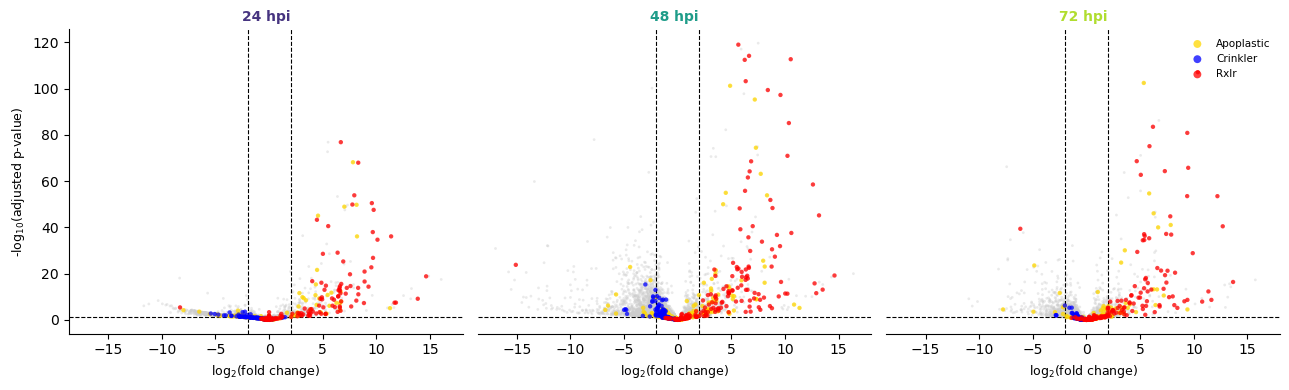

In [18]:
# ── Volcano plots: log2FC vs. -log10(padj), one per timepoint, effectors overplotted ──
import seaborn as sns

def plot_volcano_panel(ax, timepoint_label, letter=None, show_yaxis=True, legend=False):
    """Draws one timepoint's volcano plot into `ax`: every gene in light gray, RXLR/
    Crinkler/Apoplastic effectors overplotted in their category colors (Apoplastic and
    Crinkler drawn first, RXLR last/on top, since RXLR is the largest and most
    scrutinized family in this manuscript). Shared y-axis convention with Figure 4's
    coverage panels: only the leftmost panel keeps its own y-axis when embedded in a
    row of several. Used both standalone below and embedded in Supplementary Figure S3's
    final layout, so both share this exact code."""
    t_key = {v: k for k, v in TIME_LABELS.items()}[timepoint_label]
    lfc = de_full[f"{t_key}LFC"]
    pval = de_full[f"{t_key}pval"].clip(lower=np.finfo(float).tiny)
    neglog10p = -np.log10(pval)

    ax.scatter(lfc, neglog10p, s=4, color="#cccccc", alpha=0.4, edgecolor="none", zorder=1)
    for cat in ["APOPLASTIC", "CRINKLER", "RXLR"]:
        ids = gene_category2[gene_category2 == cat].index.intersection(de_full.index)
        ax.scatter(lfc.loc[ids], neglog10p.loc[ids], s=10, color=CATEGORY_COLORS[cat],
                   alpha=0.75, edgecolor="none", label=cat.capitalize(), zorder=3)

    ax.axvline(LFC_THRESHOLD, color="black", linestyle="--", linewidth=0.8, zorder=2)
    ax.axvline(-LFC_THRESHOLD, color="black", linestyle="--", linewidth=0.8, zorder=2)
    ax.axhline(-np.log10(PVAL_THRESHOLD), color="black", linestyle="--", linewidth=0.8, zorder=2)
    ax.set_xlabel("log$_2$(fold change)", fontsize=9)
    if show_yaxis:
        ax.set_ylabel("-log$_{10}$(adjusted p-value)", fontsize=9)
    sns.despine(ax=ax, left=not show_yaxis)
    if not show_yaxis:
        ax.tick_params(left=False, labelleft=False)
    ax.set_title(timepoint_label, fontsize=10, fontweight="bold", color=TIMEPOINT_COLORS[timepoint_label])
    if legend:
        ax.legend(frameon=False, fontsize=7.5, loc="upper right", markerscale=1.8)
    if letter:
        ax.text(-0.12, 1.15, letter, transform=ax.transAxes, fontsize=16,
                fontweight="bold", va="top", ha="left")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, sharex=True)
for j, t_label in enumerate(["24 hpi", "48 hpi", "72 hpi"]):
    plot_volcano_panel(axes[j], t_label, show_yaxis=(j == 0), legend=(j == 2))
plt.tight_layout()
os.makedirs("outputs/fig_sup3", exist_ok=True)
plt.savefig("outputs/fig_sup3/volcano_plots.png", dpi=300, bbox_inches="tight")
plt.show()


## Expression-profile clusters among non-Crinkler effectors (Supplementary Figure S3, panels B-C)

Looks for discrete kinetic "programs" among effector genes with a significant
expression change, independent of Figure 3's curated 27-gene panel (which shows
expression level, not this kind of aggregate kinetic clustering). Feeds Supplementary
Figure 3's panels B (mean log2FC profile per program) and C (RXLR/apoplastic
composition per program).

Looks for discrete kinetic "programs" among effector genes with any significant
expression change (|log2FC| > 2, adjusted p < 0.05, at >=1 of the three in-planta
timepoints -- the same magnitude cutoff used everywhere else in this notebook
(the 496/153/81/72 DE counts in Results), applied symmetrically
here via `abs()` so it also catches repression instead of only induction),
restricted to RXLR and apoplastic effectors. **Crinkler is excluded** -- see the
Supplementary Figure on Crinkler mapping-quality diagnostics: multi-mapping among
CRN paralogs makes its expression/copy-number calls unreliable, so folding it into a
clustering analysis meant to find genuine biological programs would risk mixing a
real signal with an artifact.

An earlier version of this cutoff used |log2FC| > 1 specifically for this section,
looser than the threshold used everywhere else, on the reasoning that repression
signatures are typically smaller in magnitude than the strongest inductions and
might be lost entirely at the stricter cutoff. Checking that against the real data:
median peak |log2FC| genuinely is smaller for repressed genes than induced ones
(3.18 vs. 5.35), but the actual effect of raising the cutoff from 1 to 2 turned out
to be a similar-sized trim on both sides (about 9-11% of genes lost from each
direction, not a wipeout of repression specifically), and none of the named AVR loci
discussed below were anywhere near the boundary either way. Kept at |log2FC| > 2
here for consistency with the rest of the manuscript's thresholds -- one number to
justify instead of two.

**Revised approach (magnitude-based clustering was too coarse).** A first version of
this analysis ran k-means directly on the raw 3-timepoint log2FC values. That groups
genes by *how induced* they are, not by *when* they turn on or off, so genes with very
different kinetics but similar overall magnitude got merged, and genes with the same
kinetics but different magnitude got split apart. Concretely: AVR-blb2 (PITG_20300,
PITG_04090; profiles [5.9, 10.5, 10.4] and [6.9, 9.6, 9.4]) and both AVR2 loci
(PITG_08943, PITG_22870; profiles ~[9.6-9.7, 10.2-10.4, 9.4-9.5]) all landed in the
same "very strong induction" cluster under magnitude-based clustering, despite AVR-blb2
rising sharply from 24 to 48 hpi while AVR2 is already near its plateau at 24 hpi; AVR3a
(profile [5.5, 6.3, 6.2]) -- which shares AVR-blb2's rising shape -- landed in a
*different* cluster purely because its magnitude is lower.

The fix: cluster on each gene's **shape**, not its magnitude, by z-scoring each gene's
own 3-timepoint profile (subtract its own mean, divide by its own SD) before k-means --
this strips out overall amplitude and keeps only the relative kinetic pattern. Doing
this on the full significant-change pool at once, however, mixes induced and repressed
genes that happen to share a similar *relative* shape (e.g., a gene induced 10 -> 8 -> 2
and a gene repressed -2 -> -4 -> -10 both "decline" in z-scored shape, despite opposite
biology) -- in an initial test, one shape cluster was 33% net-repressed genes despite
being grouped with mostly-induced ones. So clustering here is two-step: **(1)** split by
overall direction first (induced: mean log2FC > 0; repressed: mean log2FC <= 0), **(2)**
k-means on z-scored shape *within* each direction (`K_INDUCED = 3`, `K_REPRESSED = 2`,
chosen by inspecting inertia and cluster interpretability at k = 2-4 for each group --
see Result below for what each program looks like). This keeps the induction/silencing
framing while resolving the kinetic diversity within each side that the original single
clustering pass couldn't see.

In [19]:
# ── Config ────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

CLUSTER_LFC_TSV_PATH   = "inputs/tabla_LFC_pvalor.tsv"
CLUSTER_EFFECTORS_XLSX = "inputs/tabla_efectores.xlsx"
CLUSTER_LFC_THRESHOLD  = 2.0     # |log2FC| > 2 -- same magnitude cutoff as the heatmap's (Figure 3F), applied symmetrically here to also catch repression
CLUSTER_PVAL_THRESHOLD = 0.05
CLUSTER_TIME_LABELS    = {"T3": "24 hpi", "T4": "48 hpi", "T5": "72 hpi"}
K_INDUCED   = 3   # shape clusters within induced genes (mean log2FC > 0)
K_REPRESSED = 2   # shape clusters within repressed genes (mean log2FC <= 0)
N_KMEANS_SEEDS = 15

# Colors: a single viridis scale across all 5 programs by overall induction/
# repression magnitude (mean raw profile across the 3 timepoints), assigned once
# clusters are built below (cluster_centroids_raw) -- darkest violet = most
# repressed program, yellow = most induced, so hue reads consistently as
# "direction and strength" across all 5 programs at a glance, and matches the
# viridis scale used elsewhere in this notebook (Panel C's heatmap, the wrap-up v2
# category colors) rather than a separate green/red hue pair.

In [20]:
# --- Load LFC / p-value table (ignoring T1 and T2), self-contained copy (independent of Panel C's heatmap) ---
_cl_lfc_full = pd.read_csv(CLUSTER_LFC_TSV_PATH, sep="\t", index_col=0)

_cl_keep_lfc  = [f"{t}LFC"  for t in CLUSTER_TIME_LABELS]
_cl_keep_pval = [f"{t}pval" for t in CLUSTER_TIME_LABELS]

cluster_lfc  = _cl_lfc_full[_cl_keep_lfc].rename(columns=lambda c: CLUSTER_TIME_LABELS[c.replace("LFC", "")])
cluster_pval = _cl_lfc_full[_cl_keep_pval].rename(columns=lambda c: CLUSTER_TIME_LABELS[c.replace("pval", "")])

_cl_col_order = [CLUSTER_TIME_LABELS[t] for t in ["T3", "T4", "T5"]]
cluster_lfc, cluster_pval = cluster_lfc[_cl_col_order], cluster_pval[_cl_col_order]

# --- Effector table: category mapping, Crinkler excluded from the pool entirely ---
_cl_eff_df = pd.read_excel(CLUSTER_EFFECTORS_XLSX)
_cl_eff_df["Gene_ID"] = _cl_eff_df["Gene_ID"].astype(str).str.strip()
_cl_eff_df["Effector type"] = _cl_eff_df["Effector type"].astype(str).str.strip().str.upper()

def cluster_categorize(etype):
    return "RXLR" if etype == "RXLR" else "APOPLASTIC"

_cl_non_crn = _cl_eff_df[_cl_eff_df["Effector type"] != "CRINKLER"].copy()
_cl_non_crn["Category"] = _cl_non_crn["Effector type"].apply(cluster_categorize)
cluster_gene_category = _cl_non_crn.set_index("Gene_ID")["Category"]
cluster_gene_subtype  = _cl_non_crn.set_index("Gene_ID")["Effector type"]

# --- Restrict to non-Crinkler effectors with complete LFC/p-value data ---
_cl_ids = cluster_gene_category.index
cluster_lfc  = cluster_lfc.loc[cluster_lfc.index.intersection(_cl_ids)].dropna(how="any")
cluster_pval = cluster_pval.loc[cluster_pval.index.intersection(_cl_ids)].dropna(how="any")
_cl_common = cluster_lfc.index.intersection(cluster_pval.index)
cluster_lfc, cluster_pval = cluster_lfc.loc[_cl_common], cluster_pval.loc[_cl_common]

print(f"Non-Crinkler effectors with complete 3-timepoint LFC/p-value data: {len(cluster_lfc)}")

Non-Crinkler effectors with complete 3-timepoint LFC/p-value data: 308


In [21]:
# --- Keep genes with a significant change in either direction at >=1 timepoint ---
_cl_sig_mask = (cluster_pval < CLUSTER_PVAL_THRESHOLD) & (cluster_lfc.abs() > CLUSTER_LFC_THRESHOLD)
_cl_has_signal = _cl_sig_mask.any(axis=1)
cluster_genes = cluster_lfc.index[_cl_has_signal]
cluster_X = cluster_lfc.loc[cluster_genes].values
print(f"Genes with a significant change (|log2FC| > {CLUSTER_LFC_THRESHOLD}, "
      f"adjusted p < {CLUSTER_PVAL_THRESHOLD}) at >=1 timepoint: {len(cluster_genes)}")

# --- Dependency-free k-means (same from-scratch-implementation convention as ---
# --- elsewhere in this notebook, e.g. the AVR-blb2 neighbor-joining tree)    ---
def _kmeans(X, k, n_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), k, replace=False)
    centroids = X[idx].copy()
    for _ in range(n_iter):
        d = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(-1)
        labels = d.argmin(1)
        new_centroids = np.array([
            X[labels == j].mean(0) if (labels == j).sum() > 0 else centroids[j]
            for j in range(k)
        ])
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids
    inertia = sum(((X[labels == j] - centroids[j]) ** 2).sum() for j in range(k))
    return labels, centroids, inertia

def _best_kmeans(X, k, n_seeds=N_KMEANS_SEEDS):
    best = None
    for seed in range(n_seeds):
        labels, centroids, inertia = _kmeans(X, k, seed=seed)
        if best is None or inertia < best[0]:
            best = (inertia, labels, centroids)
    return best

# --- Step 1: split by overall direction (mean log2FC across the 3 timepoints) ---
_cl_mean_profile = cluster_X.mean(axis=1)
_cl_induced_mask = _cl_mean_profile > 0
_cl_repressed_mask = ~_cl_induced_mask
print(f"Induced (mean log2FC > 0): {_cl_induced_mask.sum()}  |  "
      f"Repressed (mean log2FC <= 0): {_cl_repressed_mask.sum()}")

# --- Step 2: k-means on z-scored (shape-only) profiles, separately per direction ---
PROGRAM_NAMES = []
cluster_labels = np.full(len(cluster_genes), "", dtype=object)
cluster_centroids_raw = {}  # program name -> mean RAW (not z-scored) profile, for plotting
_cl_gene_to_idx = {g: i for i, g in enumerate(cluster_genes)}

for _direction, _mask, _k, _names_hint in [
    ("induced",   _cl_induced_mask,   K_INDUCED,   ["Late, sustained", "Mid-course peak", "Early peak"]),
    ("repressed", _cl_repressed_mask, K_REPRESSED, ["Early, transient", "Delayed, progressive"]),
]:
    _Xg = cluster_X[_mask]
    _genes_g = cluster_genes[_mask]
    _mu = _Xg.mean(axis=1, keepdims=True)
    _sd = _Xg.std(axis=1, keepdims=True)
    _sd_safe = np.where(_sd < 1e-6, 1.0, _sd)
    _Xshape = (_Xg - _mu) / _sd_safe

    _, _labels, _centroids = _best_kmeans(_Xshape, _k)
    # Order shape-clusters by their 24 hpi z-score (ascending -> "starts low, rises"
    # first, "starts high, declines" last), which is what the *_names_hint lists assume.
    _order = np.argsort(_centroids[:, 0])
    _relabel = {old: new for new, old in enumerate(_order)}
    _labels_ordered = np.array([_relabel[l] for l in _labels])

    for _j in range(_k):
        _name = f"{_direction.capitalize()} -- {_names_hint[_j]}"
        PROGRAM_NAMES.append(_name)
        _m = _labels_ordered == _j
        cluster_centroids_raw[_name] = _Xg[_m].mean(axis=0)
        for _gid in _genes_g[_m]:
            cluster_labels[_cl_gene_to_idx[_gid]] = _name

# --- Program colors: single viridis scale by overall induction/repression      ---
# --- magnitude (mean raw profile across the 3 timepoints), computed now that    ---
# --- cluster_centroids_raw is fully populated for all 5 programs. Darkest violet ---
# --- = most repressed program, yellow = most induced -- see the config cell for  ---
# --- the rationale.                                                              ---
_cl_program_score = {_name: cluster_centroids_raw[_name].mean() for _name in PROGRAM_NAMES}
_cl_order_by_score = sorted(PROGRAM_NAMES, key=lambda _n: _cl_program_score[_n])
_cl_viridis = matplotlib.colormaps["viridis"]
_cl_color_by_name = {
    _name: _cl_viridis(_i / (len(_cl_order_by_score) - 1))
    for _i, _name in enumerate(_cl_order_by_score)
}
PROGRAM_COLORS = [_cl_color_by_name[_name] for _name in PROGRAM_NAMES]

for _name in PROGRAM_NAMES:
    _n = (cluster_labels == _name).sum()
    print(f"{_name}: n={_n}, mean raw profile = {np.round(cluster_centroids_raw[_name], 2)}, "
          f"overall score = {_cl_program_score[_name]:.2f}")

Genes with a significant change (|log2FC| > 2.0, adjusted p < 0.05) at >=1 timepoint: 197
Induced (mean log2FC > 0): 158  |  Repressed (mean log2FC <= 0): 39
Induced -- Late, sustained: n=47, mean raw profile = [1.42 5.72 5.13], overall score = 4.09
Induced -- Mid-course peak: n=31, mean raw profile = [4.58 6.46 4.52], overall score = 5.19
Induced -- Early peak: n=80, mean raw profile = [6.06 5.09 3.36], overall score = 4.84
Repressed -- Early, transient: n=24, mean raw profile = [-3.76 -1.14 -0.09], overall score = -1.66
Repressed -- Delayed, progressive: n=15, mean raw profile = [-1.31 -4.32 -2.64], overall score = -2.76


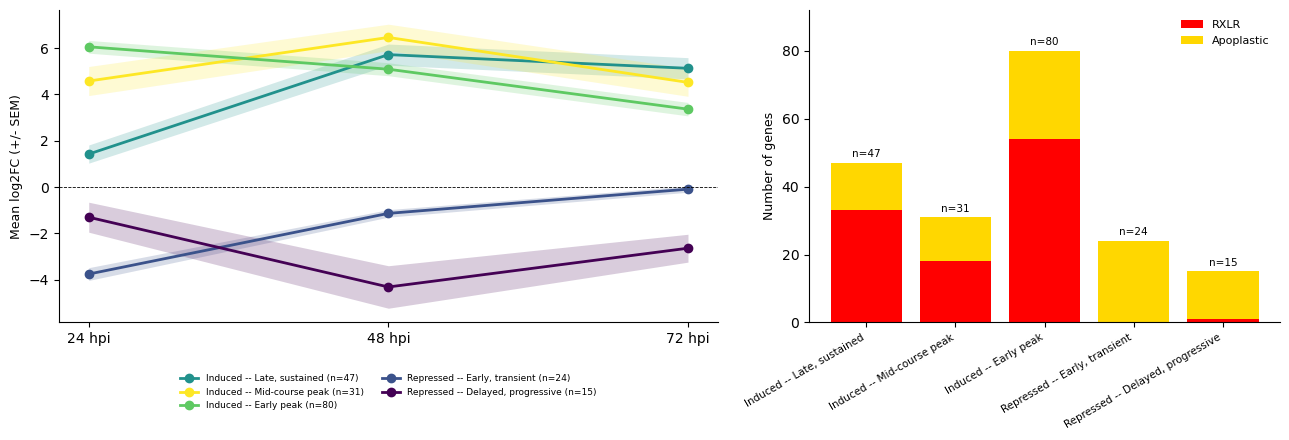

                                   RXLR  Apoplastic
Induced -- Late, sustained           33          14
Induced -- Mid-course peak           18          13
Induced -- Early peak                54          26
Repressed -- Early, transient         0          24
Repressed -- Delayed, progressive     1          14

AVR3a: program = Induced -- Late, sustained, profile = [5.51 6.33 6.19]
AVR-blb2 (PITG_20300): program = Induced -- Late, sustained, profile = [ 5.91 10.52 10.38]
AVR-blb2 (PITG_04090): program = Induced -- Late, sustained, profile = [6.91 9.57 9.39]
AVR2 (PITG_08943): program = Induced -- Mid-course peak, profile = [ 9.74 10.22  9.38]
AVR2 (PITG_22870): program = Induced -- Mid-course peak, profile = [ 9.57 10.35  9.48]


In [22]:
# --- Reusable panel functions: mean log2FC profile per program, and RXLR/apoplastic ---
# --- composition per program -- used both standalone below and embedded in           ---
# --- Supplementary Figure S3's final layout (panels B and C).                         ---
def plot_expression_mode_profiles(ax, letter=None, legend=True):
    x = np.arange(3)
    for name, color in zip(PROGRAM_NAMES, PROGRAM_COLORS):
        mask = cluster_labels == name
        profiles = cluster_X[mask]
        mean_profile = profiles.mean(axis=0)
        sem_profile = profiles.std(axis=0, ddof=1) / np.sqrt(mask.sum()) if mask.sum() > 1 else np.zeros(3)
        ax.plot(x, mean_profile, color=color, linewidth=2.0, marker="o",
                label=f"{name} (n={mask.sum()})")
        ax.fill_between(x, mean_profile - sem_profile, mean_profile + sem_profile,
                        color=color, alpha=0.2, linewidth=0)
    ax.axhline(0, color="black", linewidth=0.6, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(["24 hpi", "48 hpi", "72 hpi"])
    ax.set_ylabel("Mean log2FC (+/- SEM)", fontsize=9)
    sns.despine(ax=ax)
    if legend:
        ax.legend(frameon=False, fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
    if letter:
        ax.text(-0.15, 1.12, letter, transform=ax.transAxes, fontsize=16,
                fontweight="bold", va="top", ha="left")


def plot_expression_mode_composition(ax, letter=None):
    comp = pd.DataFrame({
        "RXLR": [((cluster_labels == name) & (cluster_gene_category.loc[cluster_genes] == "RXLR").values).sum() for name in PROGRAM_NAMES],
        "Apoplastic": [((cluster_labels == name) & (cluster_gene_category.loc[cluster_genes] == "APOPLASTIC").values).sum() for name in PROGRAM_NAMES],
    }, index=PROGRAM_NAMES)
    comp_total = comp.sum(axis=1)
    ax.bar(range(len(PROGRAM_NAMES)), comp["RXLR"], color="red", label="RXLR")
    ax.bar(range(len(PROGRAM_NAMES)), comp["Apoplastic"], bottom=comp["RXLR"], color="gold", label="Apoplastic")
    for i, name in enumerate(PROGRAM_NAMES):
        ax.text(i, comp_total[name] + comp_total.max() * 0.02, f"n={comp_total[name]}",
                ha="center", fontsize=7.5)
    ax.set_xticks(range(len(PROGRAM_NAMES)))
    ax.set_xticklabels(PROGRAM_NAMES, rotation=30, ha="right", fontsize=7.5)
    ax.set_ylabel("Number of genes", fontsize=9)
    ax.set_ylim(0, comp_total.max() * 1.15)
    sns.despine(ax=ax)
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    if letter:
        ax.text(-0.15, 1.12, letter, transform=ax.transAxes, fontsize=16,
                fontweight="bold", va="top", ha="left")
    return comp


fig, (ax_c, ax_d) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
plot_expression_mode_profiles(ax_c)
_comp = plot_expression_mode_composition(ax_d)
plt.tight_layout()
plt.savefig("outputs/fig_sup3/cluster_profiles_and_composition.png", dpi=600, bbox_inches="tight")
plt.show()
print(_comp)

# --- Where do the AVR genes that motivated this re-analysis land? ---
_avr_check = {
    "AVR3a": "PITG_14371",
    "AVR-blb2 (PITG_20300)": "PITG_20300",
    "AVR-blb2 (PITG_04090)": "PITG_04090",
    "AVR2 (PITG_08943)": "PITG_08943",
    "AVR2 (PITG_22870)": "PITG_22870",
}
print()
for _label, _gid in _avr_check.items():
    if _gid in set(cluster_genes):
        _idx = list(cluster_genes).index(_gid)
        print(f"{_label}: program = {cluster_labels[_idx]}, profile = {np.round(cluster_X[_idx], 2)}")
    else:
        print(f"{_label}: not in the significant-change pool")


**Result (run on real data): shape-based clustering resolves kinetic diversity that magnitude-based clustering couldn't see.**
158 induced and 39 repressed genes (of 197 total with a significant change, |log2FC| > 2
at >=1 timepoint) split into five programs:

- **Induced -- Early peak** (n=80, mean profile 6.06/5.09/3.36): already near-maximal
  induction at 24 hpi, declining steadily through 72 hpi. 68% RXLR.
- **Induced -- Mid-course peak** (n=31, 4.58/6.46/4.52): rises to a peak at 48 hpi, back
  down by 72 hpi. **Both AVR2 loci (PITG_08943, PITG_22870) fall here.** 58% RXLR.
- **Induced -- Late, sustained** (n=47, 1.42/5.72/5.13): low at 24 hpi, jumps sharply by
  48 hpi, and stays high through 72 hpi. **AVR3a and both AVR-blb2 paralogs (PITG_20300,
  PITG_04090) fall here** -- resolving the exact issue that motivated this re-analysis:
  under magnitude-based clustering these genes were split between "strong" and "very
  strong induction" purely by amplitude, even though they share the same delayed-onset,
  sustained kinetics. 70% RXLR.
- **Repressed -- Early, transient** (n=24, -3.76/-1.14/-0.09): sharp repression at 24
  hpi that largely resolves back toward baseline by 72 hpi. 100% apoplastic.
- **Repressed -- Delayed, progressive** (n=15, -1.31/-4.32/-2.64): mild at 24 hpi,
  deepest repression at 48 hpi, still substantially repressed at 72 hpi. 93%
  apoplastic (pectin lyase, CBEL-elicitin, cysteine protease, glucanase) -- unchanged
  from the |log2FC| > 1 run: every gene in this program already exceeded |log2FC| > 2,
  so raising the cutoff lost no members here.

Both repression programs are essentially RXLR-free (0/24 and 1/15), consistent with the
earlier magnitude-based finding that silencing is an apoplastic-specific phenomenon --
but splitting it in two shows the apoplastic repression response itself isn't uniform:
one subset is repressed early and recovers, another is repressed more slowly but more
durably. Similarly, the induced side isn't one gradient of "how strongly RXLR turns
on" -- RXLR effectors are spread across all three induction kinetics (58-70%), and
what previously read as a single "very strong induction" bucket actually contains at
least two distinct programs (already-on-by-24h vs. ramping-up-through-48h) that would
matter for hypotheses about when during infection different effectors act.

**Effect of raising the cutoff from |log2FC| > 1 to > 2 (see the markdown above):**
21 fewer genes overall (16 fewer induced -- Early peak 82->80, Mid-course 36->31, Late
sustained 56->47 -- and 5 fewer repressed -- Early, transient 29->24, Delayed
progressive unchanged at 15). Apoplastic share of the repressed set: 97.7% -> 97.4%.
RXLR share of the induced set: 63.8% -> 66.5%. All five named AVR loci checked below
keep the same program assignment either way.

## Effector mapping QC — MAPQ / coverage comparison by effector family (optional)

Checks whether the complete lack of Crinkler induction found above (Panel C above,
and confirmed by the per-timepoint upregulated-gene-set counts in the
"Differential-expression data prep" section: 0/128 annotated Crinkler genes ever
cross the induction threshold at any timepoint) could be a read-mapping artifact -- short
Illumina reads multi-mapping between near-identical Crinkler paralogs, which sit in
repeat-rich, gene-sparse genome regions and form large recently-duplicated paralog
families (Haas et al. 2009 define ~36 conserved C-terminal domain families) -- rather
than real biology. `TPM_matrix.tsv` already suggests this is real biology (Crinklers
are highly expressed in mycelium and drop during infection, rather than being
silent-then-induced like RXLRs), but this is the same class of concern already
diagnosed for the AVR-blb2 paralogs (`../../Paper Marce/avrblb2_pipeline/diagnose_avrblb2_mapq.py`),
generalized here to every annotated effector gene.

**Requires a file this notebook cannot generate on its own**:
`inputs/effector_mapping_qc_per_gene.csv` (effectors only) or, better, its
`--all-genes` extended counterpart, `inputs/effector_mapping_qc_per_gene_ext.csv`
(every gene in the genome, non-effectors tagged `OTHER`) -- produced by running
`effector_mapping_qc.py` (optionally with `--all-genes`) on the cluster (where the
RNA-seq BAMs and the genome GTF live -- see
`Paper Marce/effector_mapping_qc/README.md` for the full two-step workflow and
`run_effector_qc.sh` to launch it) and copied into `inputs/` afterwards. The
`--all-genes` version is what lets the violin panels below show the complete
transcriptome (RXLR/Crinkler/Apoplastic plus an `OTHER` violin for every other
expressed gene) instead of just the three effector families -- the same
base/extended-file fallback already used by the WGS mapping-QC section below and
by Figure 3's Panel B. The cells below check for the extended file first, fall
back to the effectors-only one, and print a clear message + skip cleanly if
neither is there yet, so this section is safe to leave in the notebook before
that's been run.

In [23]:
# ── Config + load (self-contained; needs the cluster-side CSV to have been copied ──
# ── into inputs/ first -- see the markdown cell above and Paper Marce/effector_    ──
# ── mapping_qc/README.md for how to produce it).                                   ──
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

# Prefer the extended (--all-genes) CSV if it's there -- same base/ext fallback
# pattern as the WGS mapping-QC section below and Figure 3's Panel B -- so the
# violin panel picks up the genome-wide OTHER category (every non-effector gene,
# tagged straight from the GTF) automatically once that cluster run is done;
# falls back to the effectors-only file (three categories) so this section still
# works while that run is pending.
MAPPING_QC_CSV_BASE = "inputs/effector_mapping_qc_per_gene.csv"
MAPPING_QC_CSV_EXT  = "inputs/effector_mapping_qc_per_gene_ext.csv"

if os.path.exists(MAPPING_QC_CSV_EXT):
    MAPPING_QC_CSV = MAPPING_QC_CSV_EXT
    print(f"Using extended (genome-wide) QC file: {MAPPING_QC_CSV}")
else:
    MAPPING_QC_CSV = MAPPING_QC_CSV_BASE
    print(f"Extended QC file not found ({MAPPING_QC_CSV_EXT}); falling back to "
          f"{MAPPING_QC_CSV_BASE} -- the OTHER (genome-wide) violin will be "
          f"skipped. See Paper Marce/effector_mapping_qc/README.md, 'Genome-wide run'.")

CATEGORY_COLORS = {
    "RXLR": "red",
    "CRINKLER": "blue",
    "APOPLASTIC": "gold",   # same color code as Figure 3F (the heatmap) / the Supplementary Figure above
    "OTHER": "#888888",     # genome-wide background, only present in an --all-genes QC run (WGS section below)
}
CATEGORY_LABELS = {
    "RXLR": "RXLR", "CRINKLER": "Crinkler", "APOPLASTIC": "Apoplastic",
    "OTHER": "Other\n(genome-wide)",
}
CATEGORY_ORDER_PREFERRED = ["RXLR", "CRINKLER", "APOPLASTIC", "OTHER"]
QC_METRICS = [
    ("mean_mapq", "Mean MAPQ"),
    ("frac_mapq0", "Fraction of reads with MAPQ = 0"),
    ("frac_NHgt1", "Fraction of reads multi-mapped (NH > 1)"),
    ("mean_depth", "Mean per-base depth"),
    ("breadth_1x", "Breadth of coverage (>=1x)"),
    ("breadth_10x", "Breadth of coverage (>=10x)"),
]


# Metrics plotted as log10(x + 1) instead of raw values in plot_qc_panel(). mean_depth
# spans several orders of magnitude on a genome-wide (--all-genes) run -- a handful of
# extremely highly expressed genes (rRNA, mitochondrial, other housekeeping genes) can
# sit in the hundreds of thousands while effector families are in the single/double
# digits to low hundreds, which on a linear axis flattens every other category's violin
# into an invisible sliver at the bottom. Not an issue on an effectors-only run (no
# such outliers), but harmless to apply there too.
LOG_METRICS = {"mean_depth"}
mapping_qc_available = os.path.exists(MAPPING_QC_CSV)
if mapping_qc_available:
    mapping_qc = pd.read_csv(MAPPING_QC_CSV)
    print(f"Loaded {len(mapping_qc)} genes: {mapping_qc['Category'].value_counts().to_dict()}")
else:
    mapping_qc = None
    print(
        f"Neither '{MAPPING_QC_CSV_EXT}' nor '{MAPPING_QC_CSV_BASE}' found yet.\n"
        f"Run effector_mapping_qc.py --all-genes on the cluster first (see "
        f"Paper Marce/effector_mapping_qc/README.md, 'Genome-wide run'), copy the "
        f"resulting CSV into inputs/, then re-run this section."
    )

Using extended (genome-wide) QC file: inputs/effector_mapping_qc_per_gene_ext.csv
Loaded 18179 genes: {'OTHER': 17191, 'RXLR': 557, 'APOPLASTIC': 303, 'CRINKLER': 128}


In [24]:
# --- Mann-Whitney U comparison and the violin panel, both straight from          ---
# --- effector_mapping_qc_compare.py so this notebook section and the standalone   ---
# --- script stay in sync.                                                         ---
def _auto_category_order(df, exclude=()):
    """Every Category present in df, ordered RXLR/CRINKLER/APOPLASTIC/OTHER first
    (whichever are actually present), then anything else alphabetically -- so an
    --all-genes QC run (OTHER present) is picked up automatically without every
    caller needing to pass category_order/other_categories explicitly, while an
    effectors-only run (no OTHER) looks exactly as before."""
    present = set(df["Category"].unique()) - set(exclude)
    ordered = [c for c in CATEGORY_ORDER_PREFERRED if c in present]
    ordered += sorted(present - set(ordered))
    return ordered


def compare_categories(df, metrics=QC_METRICS, ref_category="CRINKLER",
                        other_categories=None):
    if other_categories is None:
        other_categories = _auto_category_order(df, exclude={ref_category})
    rows = []
    for col, label in metrics:
        ref_vals = df.loc[df["Category"] == ref_category, col].dropna()
        row = {"metric": label, f"{ref_category}_median": ref_vals.median(),
               f"{ref_category}_n": len(ref_vals)}
        for other in other_categories:
            other_vals = df.loc[df["Category"] == other, col].dropna()
            row[f"{other}_median"] = other_vals.median()
            row[f"{other}_n"] = len(other_vals)
            if len(ref_vals) > 0 and len(other_vals) > 0:
                stat, p = mannwhitneyu(ref_vals, other_vals, alternative="two-sided")
                row[f"{ref_category}_vs_{other}_pvalue"] = p
            else:
                row[f"{ref_category}_vs_{other}_pvalue"] = float("nan")
        rows.append(row)
    return pd.DataFrame(rows)


def plot_qc_panel(df, metrics=QC_METRICS, category_order=None, max_strip_n=2000, axes=None):
    """Violin plot per metric, instead of a boxplot: OTHER can be ~17,000 genes vs.
    ~100-500 for an effector family, and a boxplot collapses that whole distribution
    to five numbers -- a violin shows the actual shape at any n. Individual points
    are still overlaid via stripplot, but only for categories small enough
    (<=max_strip_n) that the points stay informative rather than an opaque blob.
    category_order=None auto-detects every Category present (see
    _auto_category_order), so this is unchanged on an effectors-only run and adds
    the OTHER violin automatically once the extended (--all-genes) CSV is loaded."""
    sns.set_style("ticks")
    if category_order is None:
        category_order = _auto_category_order(df)
    palette = [CATEGORY_COLORS.get(c, "#888888") for c in category_order]
    tick_labels = [CATEGORY_LABELS.get(c, c) for c in category_order]

    n = len(metrics)
    if axes is None:
        ncols = 3
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.6 * nrows))
        axes = np.array(axes).reshape(-1)
        owns_figure = True
    else:
        axes = np.asarray(axes).reshape(-1)
        fig = axes[0].figure
        owns_figure = False

    for ax, (col, label) in zip(axes, metrics):
        if df[col].notna().sum() == 0:
            # e.g. frac_NH1/frac_NHgt1 on a BAM whose aligner never sets the NH tag --
            # BWA-MEM (used for the WGS bam) doesn't set it by default, only
            # STAR/HISAT2 (used for RNA-seq) do -- skip cleanly instead of crashing
            # on an entirely-NaN column.
            ax.text(0.5, 0.5, "not available\n(no data for this metric\nin this BAM/aligner)",
                    ha="center", va="center", fontsize=9, color="gray", transform=ax.transAxes)
            ax.set_title(label, fontsize=11, fontweight="bold")
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            continue

        # Plot log10(x + 1) instead of the raw column for metrics in LOG_METRICS (see
        # its definition above) -- a separate column so the underlying df/strip-plot
        # filtering below still reference the real values.
        if col in LOG_METRICS:
            plot_col = f"_log10_{col}"
            df = df.assign(**{plot_col: np.log10(df[col] + 1)})
            y_label = f"{label}\n(log10(x + 1))"
        else:
            plot_col = col
            y_label = label

        # NOTE: intentionally NOT using hue=/legend= here (only supported on
        # seaborn >=0.12) -- palette as a plain color list keeps this working on
        # older seaborn installs too (just a harmless FutureWarning on newer ones).
        sns.violinplot(
            data=df, x="Category", y=plot_col, order=category_order,
            palette=palette, cut=0, inner="quartile", linewidth=1.1,
            saturation=0.85, ax=ax,
        )
        for line in ax.lines:
            line.set_alpha(0.6)  # de-emphasize the inner quartile lines a bit

        strip_categories = [
            c for c in category_order
            if df.loc[df["Category"] == c, col].notna().sum() <= max_strip_n
        ]
        if strip_categories:
            sns.stripplot(
                data=df[df["Category"].isin(strip_categories)], x="Category", y=plot_col,
                order=category_order, color="black", alpha=0.35, size=2.5, jitter=0.25, ax=ax,
            )

        ax.set_xlabel("")
        ax.set_xticks(range(len(category_order)))
        ax.set_xticklabels(tick_labels, fontsize=8.5, rotation=20, ha="right")
        ax.set_ylabel(y_label, fontsize=10)
        ax.set_title(label, fontsize=11, fontweight="bold")
        ax.spines[["top", "right"]].set_visible(False)

    for ax in axes[n:]:
        ax.axis("off")

    if owns_figure:
        plt.tight_layout()
        return fig
    return axes


Crinkler vs. RXLR / apoplastic, Mann-Whitney U p-values:
                                 metric  CRINKLER_median  CRINKLER_n  RXLR_median  RXLR_n  CRINKLER_vs_RXLR_pvalue  APOPLASTIC_median  APOPLASTIC_n  CRINKLER_vs_APOPLASTIC_pvalue  OTHER_median  OTHER_n  CRINKLER_vs_OTHER_pvalue
                              Mean MAPQ          29.4200         125       60.000     442             1.633607e-28             60.000           281                   1.252501e-27        60.000    16060              2.904097e-47
        Fraction of reads with MAPQ = 0           0.0330         125        0.000     442             1.718311e-31              0.000           281                   1.951370e-32         0.000    16060              5.693967e-62
Fraction of reads multi-mapped (NH > 1)           0.5150         125        0.000     442             3.284480e-28              0.000           281                   1.817771e-27         0.000    16060              3.750679e-48
                    Mean per-ba

C:\Users\Marce\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Marce\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Marce\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\Marce\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future vers

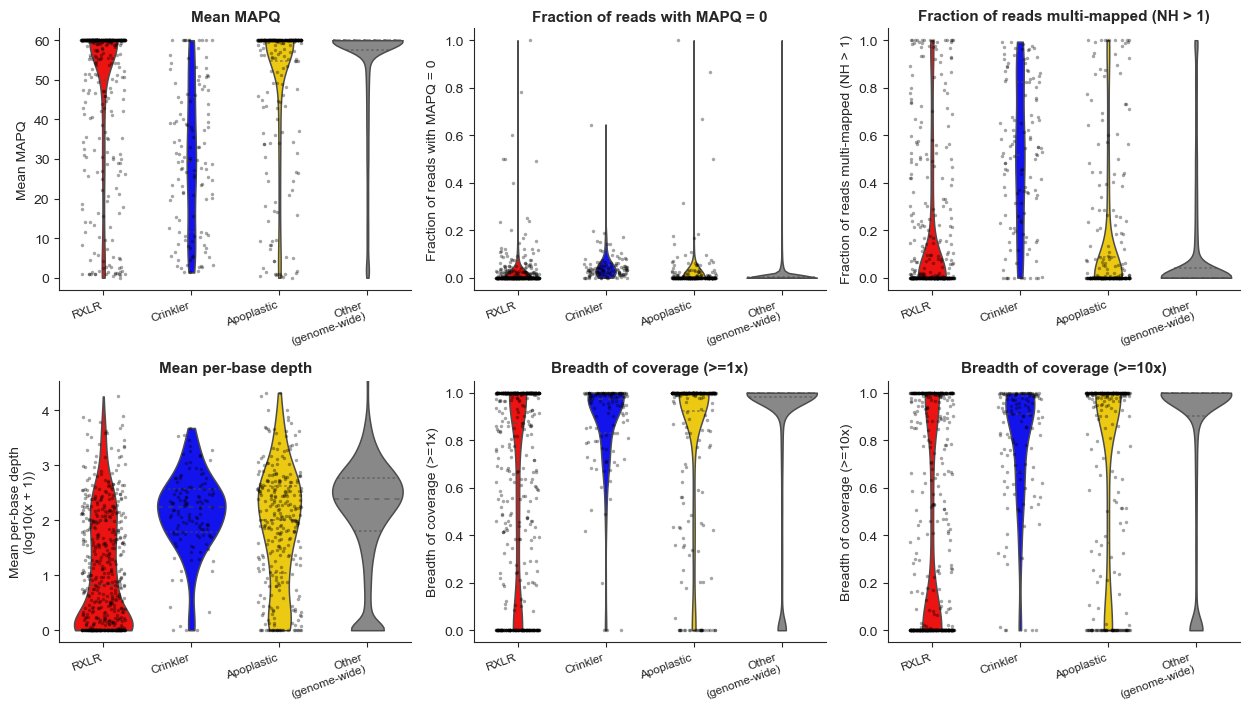


Saved outputs/fig_sup4/effector_mapping_qc_comparison.png and effector_mapping_qc_stats.csv


In [25]:
# --- Run the comparison + plot, only if the cluster-side CSV has been loaded ---
if mapping_qc_available:
    stats_df = compare_categories(mapping_qc)
    print("Crinkler vs. RXLR / apoplastic, Mann-Whitney U p-values:")
    print(stats_df.to_string(index=False))

    fig = plot_qc_panel(mapping_qc)
    os.makedirs("outputs/fig_sup4", exist_ok=True)
    fig.savefig("outputs/fig_sup4/effector_mapping_qc_comparison.png", dpi=300, bbox_inches="tight")
    stats_df.to_csv("outputs/fig_sup4/effector_mapping_qc_stats.csv", index=False)
    plt.show()
    print("\nSaved outputs/fig_sup4/effector_mapping_qc_comparison.png and "
          "effector_mapping_qc_stats.csv")
else:
    print("Skipped (see message above).")


**Result (run on real cluster data, 2026-09-11): mapping quality is NOT comparable
across categories -- Crinkler genes map substantially worse.** Median MAPQ for
Crinkler is 29.4 vs. 60 for both RXLR and apoplastic (Mann-Whitney U, p < 0.001 vs.
each); the fraction of multi-mapped reads (NH > 1) has a median of 51.5% for Crinkler
vs. ~0% for RXLR and apoplastic (p < 0.001). Crinkler loci are not under-covered --
if anything their breadth/depth of coverage is as high or higher than the other
families -- but that coverage is substantially built from ambiguously-mapped reads
shared across near-identical paralogs, not uniquely-assigned ones. This means the
apparently high Crinkler TPM in mycelium (`TPM_matrix.tsv`) is at least partly
inflated by cross-paralog multi-mapping rather than being purely real single-locus
expression, and the "0/128 Crinkler genes ever induced" result should be reported
with this caveat rather than as a clean biological finding: a substantial fraction of
Crinkler read support is not uniquely attributable to the specific gene model DESeq2
is testing, so the DE calls for this family are less trustworthy than for RXLR/
apoplastic. Consider re-running the Crinkler DE analysis restricted to uniquely-
mapped (NH == 1) reads only, or collapsing counts to the paralog-family level, before
finalizing the Discussion's interpretation of this family's expression pattern.

**Genome-wide context (`--all-genes`, 2026-09-12):** re-running the same QC with every gene in the GTF (not just the annotated effectors) adds a genuine genome-wide background category (`OTHER`, n=17,191) to the comparison above. `OTHER` maps essentially perfectly (median MAPQ 60, 0% MAPQ=0, 0% multi-mapped, 100% breadth >=1x) -- indistinguishable from RXLR/apoplastic and in sharp contrast to Crinkler, confirming that Crinkler's degraded mapping profile is a property of that specific paralog family rather than a general artifact of this RNA-seq dataset or pipeline. `OTHER`'s mean-depth distribution has a long right tail (a handful of very highly expressed genes, e.g. rRNA/mitochondrial/ other housekeeping genes, reaching into the hundreds of thousands), which flattened the other categories' violins on a linear axis; the depth panel is now plotted as log10(x + 1) to keep all four categories legible (medians themselves are unaffected, reported on the original scale above and in `effector_mapping_qc_stats.csv`).


## Effector mapping QC — genomic (WGS) reads and copy-number correlation (optional)

Extends the mapping QC above from RNA-seq to the whole-genome sequencing (WGS) reads
that the genomic copy-number calls (`gene_ploidy_v2.csv`, plotted in the "Gene copy
number per effector family" section above -- not part of any current figure) are
built from. The RNA-seq section above showed Crinkler genes map substantially worse
than RXLR/apoplastic in RNA-seq (median MAPQ 29.4 vs. 60, 51.5% vs. ~0% multi-mapped).
Crinkler also shows a lower assigned copy-number distribution than RXLR/apoplastic
in the unfiltered data (the "Gene copy number per effector family" section above) -- an
effect that attenuated, in an earlier version of this notebook, once restricted to
well-mapped genes (that filtered panel isn't part of any current figure; see
"Supplementary Figure S3 (final layout)" further below for the underlying
mapping-quality evidence) -- and the copy-number pipeline (Knaus et al. 2020 method: GATK
HaplotypeCaller gVCF allele-balance + samtools mpileup depth, see Methods) is, like
DESeq2, built on short-read alignments that exclude or down-weight multi-mapped/
low-MAPQ reads during genotyping. If the same Crinkler paralogs that multi-map in
RNA-seq also multi-map in the WGS data, that would tend to bias copy-number calls
**downward** at exactly these loci -- the opposite-looking effect (fewer apparent
copies rather than fewer induced reads) but the same underlying mechanism. The
manuscript's existing technical-artifact check for this (Results: Crinkler genes are
not disproportionately high-GC or on short/gene-dense contigs) only tests indirect
proxies for repetitiveness, not mapping quality at these loci directly.

**Requires two files this notebook cannot generate on its own**:
- `inputs/effector_mapping_qc_wgs_per_gene.csv` -- same script as the RNA-seq section
  (`effector_mapping_qc.py`), run on the cluster restricted to the WGS BAM only
  (`--only pinsl.bam`; `Paper Marce/effector_mapping_qc/run_effector_qc_wgs.sh`
  wraps this). See `Paper Marce/effector_mapping_qc/README.md` for the full
  workflow.
- `inputs/gene_ploidy_v2.csv` -- already used above (the "Gene copy number per
  effector family" section), reused here
  to pull in each gene's assigned copy number for the copy-number correlation step
  below.

The cells below check for both files and print a clear message + skip cleanly if
either isn't there yet, so this section is safe to leave in the notebook before
the WGS run has been done.

**Note on metrics**: the WGS BAM was aligned with BWA-MEM (see Methods), which -- unlike STAR/HISAT2, used for the RNA-seq BAMs above -- does not set the NH:i tag by default. `frac_NH1`/`frac_NHgt1` are therefore undefined (all-NaN) for the WGS run; `plot_qc_panel()` shows those two panels as "not available" instead of crashing. `frac_mapq0` (fraction of reads with MAPQ = 0) plays the equivalent role here -- for BWA-MEM it's the standard multi-mapping signature -- and is fully populated.

**Genome-wide comparison (optional)**: if `inputs/effector_mapping_qc_wgs_per_gene_ext.csv`
is present (produced by `effector_mapping_qc.py --all-genes`, see
`Paper Marce/effector_mapping_qc/README.md`, "Genome-wide run"), it's used instead of
the base file and the violin panel below adds a fourth, genome-wide `OTHER` category
so RXLR/Crinkler/apoplastic can be read against the rest of the genome, not just
against each other. Falls back to the effector-only file (three categories) with a
printed note if that extended run hasn't been done yet.

In [26]:
# ── Config + load (self-contained; needs the cluster-side WGS CSV to have been ──
# ── copied into inputs/ first -- see the markdown cell above and Paper Marce/    ──
# ── effector_mapping_qc/README.md for how to produce it). gene_ploidy_v2.csv is  ──
# ── already loaded above (the Supplementary Figure's Panel A) but re-read here   ──
# ── to keep this section independently runnable.                                 ──
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# Prefer the extended (--all-genes) CSV if it's there -- same base/ext fallback
# pattern as Figure 3's Panel B above -- so the violin panel below picks up the
# genome-wide OTHER category automatically once that cluster run is done; falls
# back to the effectors-only file (three categories) so this section still works
# while that run is pending.
WGS_MAPPING_QC_CSV_BASE = "inputs/effector_mapping_qc_wgs_per_gene.csv"
WGS_MAPPING_QC_CSV_EXT  = "inputs/effector_mapping_qc_wgs_per_gene_ext.csv"
PLOIDY_CSV = "inputs/gene_ploidy_v2.csv"

if os.path.exists(WGS_MAPPING_QC_CSV_EXT):
    WGS_MAPPING_QC_CSV = WGS_MAPPING_QC_CSV_EXT
    print(f"Using extended (genome-wide) QC file: {WGS_MAPPING_QC_CSV}")
else:
    WGS_MAPPING_QC_CSV = WGS_MAPPING_QC_CSV_BASE
    print(f"Extended QC file not found ({WGS_MAPPING_QC_CSV_EXT}); falling back to "
          f"{WGS_MAPPING_QC_CSV_BASE} -- the OTHER (genome-wide) violin will be "
          f"skipped. See Paper Marce/effector_mapping_qc/README.md, 'Genome-wide run'.")

mapping_qc_wgs_available = os.path.exists(WGS_MAPPING_QC_CSV)
if mapping_qc_wgs_available:
    mapping_qc_wgs = pd.read_csv(WGS_MAPPING_QC_CSV)
    print(f"Loaded {len(mapping_qc_wgs)} genes (WGS): "
          f"{mapping_qc_wgs['Category'].value_counts().to_dict()}")
else:
    mapping_qc_wgs = None
    print(
        f"Neither '{WGS_MAPPING_QC_CSV_EXT}' nor '{WGS_MAPPING_QC_CSV_BASE}' found "
        f"yet.\nRun effector_mapping_qc.py --only pinsl.bam (optionally --all-genes) "
        f"on the cluster first (see Paper Marce/effector_mapping_qc/README.md / "
        f"run_effector_qc_wgs.sh), copy the resulting CSV into inputs/, then "
        f"re-run this section."
    )

ploidy_available = os.path.exists(PLOIDY_CSV)
if ploidy_available:
    ploidy_df = pd.read_csv(PLOIDY_CSV)
else:
    ploidy_df = None
    print(f"'{PLOIDY_CSV}' not found -- needed for the copy-number correlation step below.")

Using extended (genome-wide) QC file: inputs/effector_mapping_qc_wgs_per_gene_ext.csv
Loaded 18179 genes (WGS): {'OTHER': 17191, 'RXLR': 557, 'APOPLASTIC': 303, 'CRINKLER': 128}


In [27]:
# --- Same functions as effector_mapping_qc_compare.py's WGS-specific additions, ---
# --- kept in sync so this notebook section and the standalone script match.     ---
# --- compare_categories()/plot_qc_panel() (category-level MAPQ/NH/breadth        ---
# --- comparison) are already defined above, in the RNA-seq QC section, and are  ---
# --- reused as-is here -- they take any per-gene QC dataframe with a Category    ---
# --- column, RNA-seq or WGS.                                                     ---
def correlate_with_copy_number(qc_df, ploidy_df, metrics=QC_METRICS,
                                categories=("RXLR", "CRINKLER", "APOPLASTIC")):
    """Merge per-gene WGS mapping QC with assigned copy number (gene_ploidy_v2.csv's
    `gene`/`allele` columns) and compute a Spearman correlation per category and
    metric. A significant negative rho for frac_NHgt1/frac_mapq0 (or positive for
    mean_mapq) *within* a category means genes with worse mapping in that category
    also tend to get assigned lower copy number -- a dose-response signature
    consistent with multi-mapping suppressing the apparent copy-number call, not
    just a between-category average difference."""
    ploidy = ploidy_df[["gene", "allele"]].rename(
        columns={"gene": "Gene_ID", "allele": "copy_number"}
    )
    merged = qc_df.merge(ploidy, on="Gene_ID", how="inner")

    rows = []
    for cat in categories:
        sub = merged.loc[merged["Category"] == cat].dropna(subset=["copy_number"])
        for col, label in metrics:
            pair = sub[[col, "copy_number"]].dropna()
            if len(pair) >= 3:
                rho, p = spearmanr(pair[col], pair["copy_number"])
            else:
                rho, p = float("nan"), float("nan")
            rows.append({"Category": cat, "metric": label, "n": len(pair),
                         "spearman_rho": rho, "pvalue": p})
    return pd.DataFrame(rows), merged


def plot_copy_number_scatter(merged, category_order=("RXLR", "CRINKLER", "APOPLASTIC"),
                              metrics=(("mean_mapq", "Mean MAPQ (WGS)"),
                                       ("frac_NHgt1", "Fraction multi-mapped, NH > 1 (WGS)"))):
    """One panel per metric: assigned copy number (Y, jittered) vs. that gene's own
    WGS mapping-quality metric (X), points colored by effector category."""
    sns.set_style("ticks")
    n = len(metrics)
    fig, axes = plt.subplots(1, n, figsize=(5.5 * n, 4.2))
    axes = np.atleast_1d(axes)
    rng = np.random.default_rng(0)

    for ax, (col, label) in zip(axes, metrics):
        for cat in category_order:
            sub = merged.loc[merged["Category"] == cat].dropna(subset=[col, "copy_number"])
            jitter = rng.uniform(-0.12, 0.12, size=len(sub))
            ax.scatter(
                sub[col], sub["copy_number"] + jitter,
                s=16, alpha=0.5, color=CATEGORY_COLORS[cat], label=cat, edgecolor="none",
            )
        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel("Assigned copy number", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].legend(frameon=False, fontsize=9, title="Category")
    plt.tight_layout()
    return fig


WGS reads -- Crinkler vs. RXLR / apoplastic, Mann-Whitney U p-values:
                                 metric  CRINKLER_median  CRINKLER_n  RXLR_median  RXLR_n  CRINKLER_vs_RXLR_pvalue  APOPLASTIC_median  APOPLASTIC_n  CRINKLER_vs_APOPLASTIC_pvalue  OTHER_median  OTHER_n  CRINKLER_vs_OTHER_pvalue
                              Mean MAPQ          16.3450         128        58.84     545             1.734557e-31              60.00           299                   2.940250e-34         60.00    17130              5.702009e-56
        Fraction of reads with MAPQ = 0           0.4875         128         0.00     545             1.009229e-33               0.00           299                   7.811945e-32          0.00    17130              1.627418e-58
Fraction of reads multi-mapped (NH > 1)              NaN           0          NaN       0                      NaN                NaN             0                            NaN           NaN        0                       NaN
                  

C:\Users\Marce\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Marce\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Marce\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\Marce\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future vers

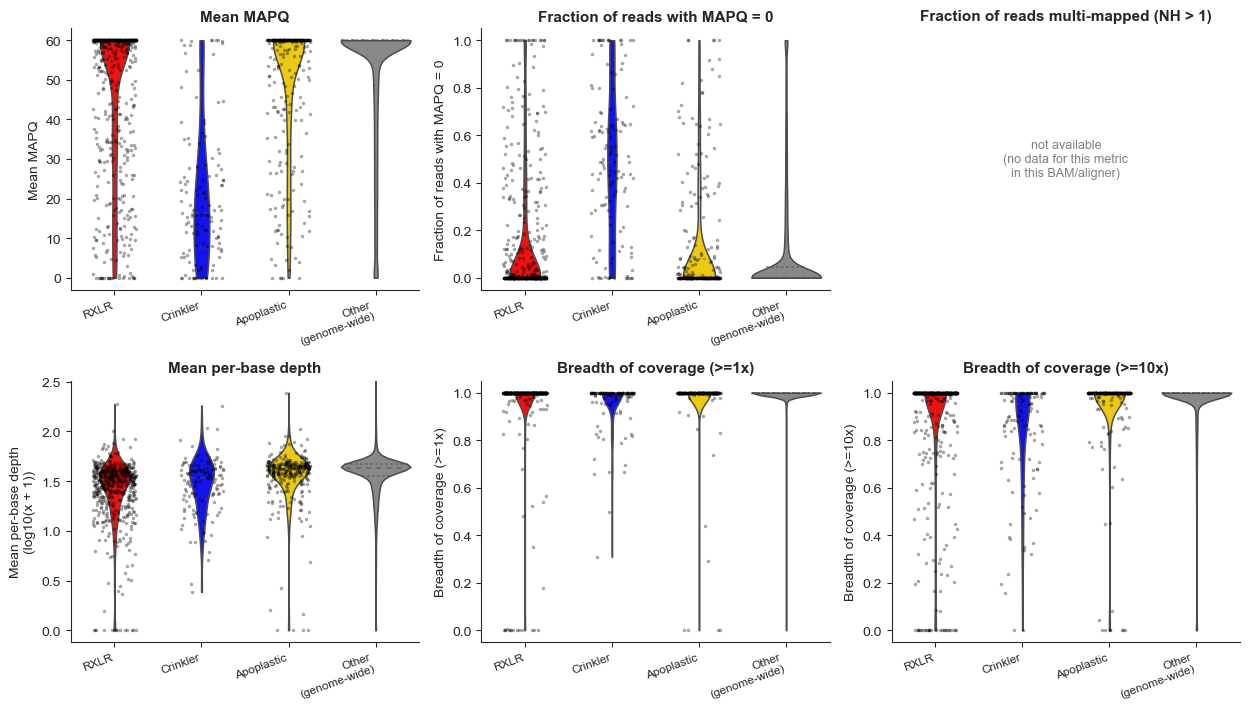


Saved outputs/fig_sup4/effector_mapping_qc_wgs_comparison.png and effector_mapping_qc_wgs_stats.csv

Copy-number correlation (Spearman rho, WGS mapping metric vs. assigned copy number, within each category):
  Category                                  metric   n  spearman_rho       pvalue
      RXLR                               Mean MAPQ 522     -0.073304 9.432019e-02
      RXLR         Fraction of reads with MAPQ = 0 522      0.076256 8.175134e-02
      RXLR Fraction of reads multi-mapped (NH > 1)   0           NaN          NaN
      RXLR                     Mean per-base depth 532      0.102552 1.797886e-02
      RXLR              Breadth of coverage (>=1x) 532      0.058884 1.750544e-01
      RXLR             Breadth of coverage (>=10x) 532      0.149951 5.201943e-04
  CRINKLER                               Mean MAPQ 126      0.201300 2.380515e-02
  CRINKLER         Fraction of reads with MAPQ = 0 126     -0.186857 3.616672e-02
  CRINKLER Fraction of reads multi-mapped (NH > 1)   

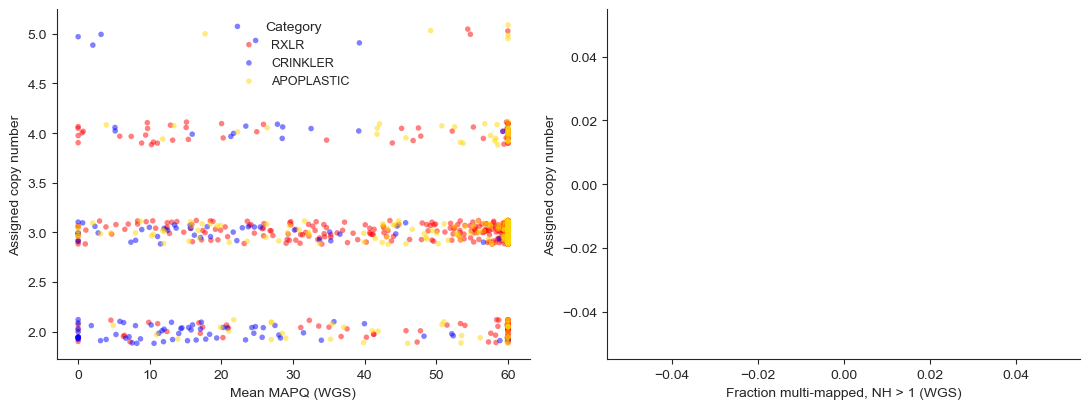


Saved outputs/fig_sup4/effector_mapping_qc_cnv_scatter.png and effector_mapping_qc_cnv_correlation.csv


In [28]:
# --- Run the WGS category-level comparison, then the copy-number correlation, ---
# --- each only if its required input file was found above.                     ---
if mapping_qc_wgs_available:
    stats_df_wgs = compare_categories(mapping_qc_wgs)
    print("WGS reads -- Crinkler vs. RXLR / apoplastic, Mann-Whitney U p-values:")
    print(stats_df_wgs.to_string(index=False))

    fig_wgs = plot_qc_panel(mapping_qc_wgs)
    os.makedirs("outputs/fig_sup4", exist_ok=True)
    fig_wgs.savefig("outputs/fig_sup4/effector_mapping_qc_wgs_comparison.png", dpi=300, bbox_inches="tight")
    stats_df_wgs.to_csv("outputs/fig_sup4/effector_mapping_qc_wgs_stats.csv", index=False)
    plt.show()
    print("\nSaved outputs/fig_sup4/effector_mapping_qc_wgs_comparison.png and "
          "effector_mapping_qc_wgs_stats.csv")

    if ploidy_available:
        cnv_stats, cnv_merged = correlate_with_copy_number(mapping_qc_wgs, ploidy_df)
        print("\nCopy-number correlation (Spearman rho, WGS mapping metric vs. "
              "assigned copy number, within each category):")
        print(cnv_stats.to_string(index=False))

        fig_cnv = plot_copy_number_scatter(cnv_merged)
        fig_cnv.savefig("outputs/fig_sup4/effector_mapping_qc_cnv_scatter.png", dpi=300, bbox_inches="tight")
        cnv_stats.to_csv("outputs/fig_sup4/effector_mapping_qc_cnv_correlation.csv", index=False)
        plt.show()
        print("\nSaved outputs/fig_sup4/effector_mapping_qc_cnv_scatter.png and "
              "effector_mapping_qc_cnv_correlation.csv")
    else:
        print("\nSkipped copy-number correlation (gene_ploidy_v2.csv not found).")
else:
    print("Skipped (see message above).")


**Result (run on real cluster data): WGS mapping quality shows the same Crinkler-specific
degradation seen in RNA-seq.** Median MAPQ for Crinkler WGS reads is 16.3, far below
both RXLR (58.8) and apoplastic (60.0); the fraction of MAPQ = 0 reads has a median of
48.8% for Crinkler vs. ~0% for RXLR/apoplastic -- the same qualitative pattern as the
RNA-seq result above (median MAPQ 29.4 vs. 60, 51.5% vs. ~0% multi-mapped), now
confirmed independently in the genomic reads that the copy-number calls are actually
built from. This supports treating Crinkler's lower assigned copy number (the "Gene
copy number per effector family" section above) as at least partly a mapping artifact
rather than a purely biological reduction in gene dosage.

**Copy-number correlation (within-category, WGS mapping metric vs. assigned copy
number):** see `outputs/fig_sup4/effector_mapping_qc_cnv_correlation.csv` for the
exact Spearman rho / p-value per category and metric; panels F-G of Supplementary
Figure 3 below plot the same relationship visually. A significant positive
correlation between mean MAPQ and assigned copy number *within* Crinkler (or negative
for fraction of MAPQ = 0 reads) would mean copy number is directly suppressed at the
specific loci that map worst, strengthening the case that this is a mapping artifact
rather than genuine biology; no such correlation would leave the artifact
interpretation resting on the between-category comparison alone -- check the CSV
above before finalizing the Discussion's wording on this point.

## AVR1 / AVR2 / AVR3a / AVR3b — mean TPM across infection timepoints

Line plot of mean TPM (across replicates) for the four effectors tied to the
R-gene specificities tested on Innovator (R1, R2, R3a, R3b), from mycelium
through 24/48/72 hpi. One color per gene (viridis), same visual style as the
potato-assay boxplot (Figure 4). Note: `TPM_efectores.tsv` carries **two**
distinct PITG loci both annotated "AVR2" (PITG_08943 and PITG_22870 — the
same locus-numbering ambiguity already flagged elsewhere in the manuscript
between Discussion and the figure legend); both are plotted separately here
rather than silently merged.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ── Config ────────────────────────────────────────────────────────────────────
TPM_TSV_PATH = "inputs/TPM_efectores.tsv"
GENE_NAMES   = ["AVR1", "AVR2", "AVR3a", "AVR3b"]
TIME_ORDER   = ["Myc", "24", "48", "72"]

# One color per GENE (not per locus), shared with the AVR gene coverage-profile
# panels below and Figure 4's final layout, so the same gene is always the same
# color in both figures. AVR2's two annotated loci share GENE_COLORS["AVR2"] and
# are told apart instead by LOCUS_LINESTYLE (solid vs. dashed) -- every other gene
# has a single locus and always gets the solid style.
GENE_ORDER      = GENE_NAMES
GENE_COLORS     = dict(zip(GENE_ORDER, sns.color_palette("viridis", n_colors=len(GENE_ORDER))))
LOCUS_LINESTYLE = {"PITG_08943": "-", "PITG_22870": "--"}  # AVR2's two loci only

# --- Load and parse the "Gene" column (comes as "PITG_id  name  type" in a single field) ---
tpm_raw = pd.read_csv(TPM_TSV_PATH, sep="\t")
gene_parts = tpm_raw["Gene"].str.split(expand=True)
tpm = pd.concat([
    gene_parts[[0, 1]].rename(columns={0: "PITG", 1: "gene_name"}),
    tpm_raw[["Time", "Experiment", "TPM"]],
], axis=1)

tpm["Time"] = tpm["Time"].astype(str).str.strip()
tpm = tpm[tpm["Time"].isin(TIME_ORDER)].copy()
tpm["Time"] = pd.Categorical(tpm["Time"], categories=TIME_ORDER, ordered=True)

sub = tpm[tpm["gene_name"].isin(GENE_NAMES)].copy()

# Label per locus: always includes the PITG id (e.g. AVR2 has two loci
# annotated with the same name -- PITG_08943 and PITG_22870 -- so the PITG id
# is what actually distinguishes each line)
def make_label(row):
    return f'{row["gene_name"]} ({row["PITG"]})'
sub["label"] = sub.apply(make_label, axis=1)

print("Loci included:")
print(sub[["gene_name", "PITG", "label"]].drop_duplicates().to_string(index=False))

Loci included:
gene_name       PITG              label
     AVR2 PITG_08943  AVR2 (PITG_08943)
    AVR3a PITG_14371 AVR3a (PITG_14371)
     AVR2 PITG_22870  AVR2 (PITG_22870)
     AVR1 PITG_16663  AVR1 (PITG_16663)
    AVR3b PITG_18215 AVR3b (PITG_18215)


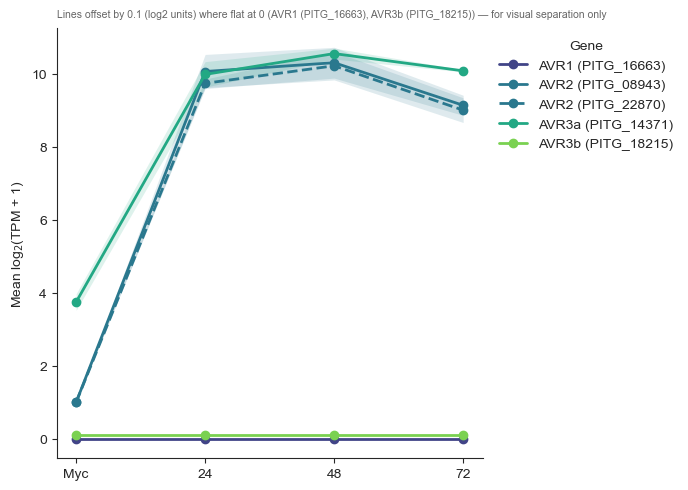

In [30]:
# ── Mean log2(TPM + 1) per gene x timepoint (across replicates/experiments) ─────
# Each individual replicate is transformed with log2(TPM + 1) (pseudocount = 1,
# to be able to include AVR1/AVR3b, which have TPM = 0) and ONLY THEN averaged --
# the raw TPM mean is not transformed directly, so that the spread (shaded band)
# correctly reflects the dispersion in log2 scale.
sub["log2_TPM"] = np.log2(sub["TPM"] + 1)

mean_tpm = (
    sub.groupby(["label", "Time"], observed=True, as_index=False)
       .agg(mean_log2TPM=("log2_TPM", "mean"), sd_log2TPM=("log2_TPM", "std"), n=("TPM", "size"))
)
mean_tpm["sd_log2TPM"] = mean_tpm["sd_log2TPM"].fillna(0.0)

tpm_labels = sorted(sub["label"].unique())
label_to_locus = sub[["label", "gene_name", "PITG"]].drop_duplicates().set_index("label")
# Color by gene (GENE_COLORS, defined above) rather than by locus -- AVR2's two loci
# share a color and are told apart by linestyle instead (LOCUS_LINESTYLE).
palette_tpm   = {lbl: GENE_COLORS[label_to_locus.loc[lbl, "gene_name"]] for lbl in tpm_labels}
linestyle_tpm = {lbl: LOCUS_LINESTYLE.get(label_to_locus.loc[lbl, "PITG"], "-") for lbl in tpm_labels}

# --- Vertical offset only for lines completely flat at 0 (AVR1 and AVR3b: TPM=0 at
# every timepoint -> log2(0+1)=0 for both -> they overlap exactly at y=0) ---
# Purely visual: the real value (log2(TPM+1)=0, i.e. TPM=0) is preserved in
# mean_tpm / clarified in the plot. Small offset since we're now in log2 scale.
FLAT_OFFSET = 0.1  # log2(TPM + 1) units
flat_labels = [
    lbl for lbl in tpm_labels
    if mean_tpm.loc[mean_tpm["label"] == lbl, "mean_log2TPM"].abs().max() < 1e-6
]
offsets = {lbl: i * FLAT_OFFSET for i, lbl in enumerate(flat_labels)}

sns.set_style("ticks")
fig, ax = plt.subplots(figsize=(7, 5))

for lbl in tpm_labels:
    d = mean_tpm[mean_tpm["label"] == lbl].set_index("Time").reindex(TIME_ORDER)
    x = np.arange(len(TIME_ORDER))
    offset = offsets.get(lbl, 0)
    y = d["mean_log2TPM"] + offset
    ax.plot(x, y, marker="o", color=palette_tpm[lbl], linewidth=2, linestyle=linestyle_tpm[lbl],
            markersize=6, label=lbl)
    ax.fill_between(x, y - d["sd_log2TPM"], y + d["sd_log2TPM"],
                     color=palette_tpm[lbl], alpha=0.15, linewidth=0)

ax.set_xticks(np.arange(len(TIME_ORDER)))
ax.set_xticklabels(TIME_ORDER)
ax.set_xlabel("")
ax.set_ylabel("Mean log$_2$(TPM + 1)")
sns.despine(ax=ax)

if flat_labels:
    ax.text(0.0, 1.02, f"Lines offset by {FLAT_OFFSET} (log2 units) where flat at 0 "
                        f"({', '.join(flat_labels)}) — for visual separation only",
            transform=ax.transAxes, fontsize=7.5, color="#666666", ha="left", va="bottom")

ax.legend(title="Gene", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.savefig("outputs/fig4/AVR1_AVR2_AVR3a_AVR3b_TPM.png", dpi=400, bbox_inches="tight", format="png")
plt.show()

## AVR gene genomic (WGS) coverage profile — feeds Figure 4, panels A-D

Per-position WGS read depth (`avr_gene_depth_profile.py`, run on the cluster
against `pinsl.bam`) across the CDS +/- 300 bp of flanking sequence, for the
same five loci as the TPM panel above: *AVR1* (PITG_16663), *AVR3a*
(PITG_14371), *AVR3b* (PITG_18215), and the two loci both annotated *AVR2*
(PITG_08943, PITG_22870). Neither `effector_mapping_qc_wgs_per_gene.csv`
(one `mean_depth`/`breadth_1x`/`breadth_10x` per gene) nor `coverage_contigs.txt`
(one row per whole contig) has per-position resolution -- this is the first
place in the notebook that does, specifically to tell "this gene has no
genomic reads at all" apart from "this gene has reads everywhere except one
sub-region."

One panel per gene (four total -- AVR2's two loci share one panel, same
color, told apart by linestyle) rather than one line per locus, so a missing
gene is immediately visible next to genes with real coverage. Colors match
the TPM panel above exactly (`GENE_COLORS`, one per gene, shared across both
figures) and so do the linestyles (`LOCUS_LINESTYLE`) -- the same gene/locus
is always the same color/linestyle in both places in Figure 4. All four
panels share one y-axis (`COVERAGE_YLIM`, raw pooled WGS depth,
`COVERAGE_DEPTH_COL = "depth"`) so coverage levels are directly comparable
across genes; each gene's CDS body (vs. its +/-300 bp flanks) is shaded in
its own color. `avr_gene_coverage_profile_mapq30.csv` also carries a
MAPQ>=30-only depth column (`depth_mapq30`) for genes where multi-mapping
might be suppressing apparent coverage (relevant for AVR2/AVR-blb2-family
loci specifically) -- swap `COVERAGE_DEPTH_COL` to use it instead if wanted.

`plot_avr_coverage_panel()` is defined once here and reused, unchanged, in
Figure 4's final layout below -- the standalone display right after this
cell and the embedded version share the exact same code.

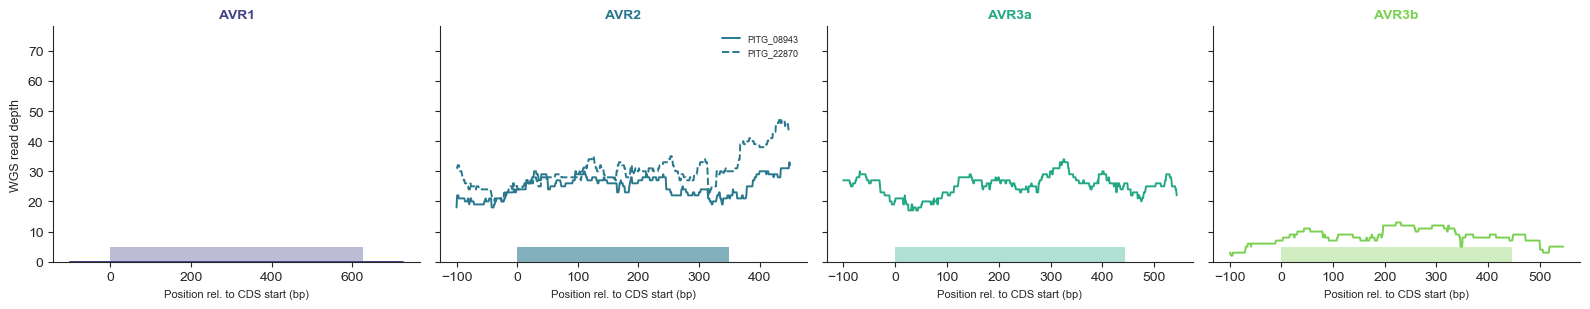

In [31]:
import os

# ── Config ──────────────────────────────────────────────────────────────────
COVERAGE_CSV_PATH  = "inputs/avr_gene_coverage_profile_mapq30.csv"
COVERAGE_DEPTH_COL = "depth"  # raw pooled WGS depth; swap to "depth_mapq30" for unique-mapping-only depth

cov = pd.read_csv(COVERAGE_CSV_PATH)

# Which Gene_ID(s) make up each of the four coverage panels, same order as
# GENE_ORDER/GENE_COLORS above.
GENE_LOCI = {
    "AVR1":  ["PITG_16663"],
    "AVR2":  ["PITG_08943", "PITG_22870"],
    "AVR3a": ["PITG_14371"],
    "AVR3b": ["PITG_18215"],
}

COVERAGE_YLIM = (0, cov[COVERAGE_DEPTH_COL].max() * 1.1)
CDS_SHADE_YMAX_DATA = 5.0  # CDS marker rectangle spans y=0..5 (data units), not the full plot height
COVERAGE_FLANK_BP = 100    # display only +/-100 bp of flanking sequence around each CDS
                           # (the underlying CSV has 300 bp of flank -- avr_gene_depth_profile.py's
                           # --flank default -- this just trims the displayed x-range)

def plot_avr_coverage_panel(ax, gene_label, letter=None, show_yaxis=True):
    """Draws one gene's WGS depth-vs-position profile into `ax`: one line per
    annotated locus (AVR2 has two, same color as the TPM panel, different
    linestyle), CDS body marked with a darker rectangle spanning y=0-5 (data
    units) in the gene's own color, shared y-axis (COVERAGE_YLIM) across all
    four panels so genes are directly comparable, x-axis trimmed to +/-
    COVERAGE_FLANK_BP around the CDS. When `show_yaxis=False` the left
    spine/ticks/label are hidden so several panels can visually share a
    single y-axis (only the leftmost panel keeps it). Used both standalone
    below and embedded in Figure 4's final layout, so both share this exact
    code."""
    color = GENE_COLORS[gene_label]
    cds_ymax_frac = CDS_SHADE_YMAX_DATA / COVERAGE_YLIM[1]
    for gene_id in GENE_LOCI[gene_label]:
        d = cov[cov["Gene_ID"] == gene_id].sort_values("gene_pos_bp")
        cds_all = d[d["in_cds"]]
        cds_min, cds_max = cds_all["gene_pos_bp"].min(), cds_all["gene_pos_bp"].max()
        d = d[(d["gene_pos_bp"] >= cds_min - COVERAGE_FLANK_BP) &
              (d["gene_pos_bp"] <= cds_max + COVERAGE_FLANK_BP)]
        ls = LOCUS_LINESTYLE.get(gene_id, "-")
        ax.plot(d["gene_pos_bp"], d[COVERAGE_DEPTH_COL], color=color,
                linewidth=1.4, linestyle=ls, label=gene_id)
        cds = d[d["in_cds"]]
        if len(cds):
            ax.axvspan(cds["gene_pos_bp"].min(), cds["gene_pos_bp"].max(),
                       ymin=0, ymax=cds_ymax_frac,
                       color=color, alpha=0.35, linewidth=0, zorder=0)
    ax.set_ylim(*COVERAGE_YLIM)
    ax.set_xlabel("Position rel. to CDS start (bp)", fontsize=8)
    ax.set_title(gene_label, fontsize=10, fontweight="bold", color=color)
    sns.despine(ax=ax, left=not show_yaxis)
    if not show_yaxis:
        ax.tick_params(left=False, labelleft=False)
    if len(GENE_LOCI[gene_label]) > 1:
        ax.legend(fontsize=6.5, frameon=False, loc="upper right")
    if letter:
        ax.text(-0.12, 1.15, letter, transform=ax.transAxes, fontsize=16,
                fontweight="bold", va="top", ha="left")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, gene_label in zip(axes, GENE_ORDER):
    plot_avr_coverage_panel(ax, gene_label)
axes[0].set_ylabel("WGS read depth", fontsize=9)
plt.tight_layout()
os.makedirs("outputs/fig4", exist_ok=True)
plt.savefig("outputs/fig4/AVR_coverage_profiles.png", dpi=300, bbox_inches="tight")
plt.show()


## Figure 4 — potato leaf infection assay (Spunta / Innovator)

Boxplot of % leaf area affected per isolate and potato variety (Spunta, Innovator),
with one representative photo per isolate/variety combination placed above (Spunta)
and below (Innovator) the corresponding boxplot column. Individual data points are
jittered within each box; points below `UMBRAL` (5% lesioned area) in Innovator are
flagged with a red X as a hypersensitive-response (HR) response rather than a
compatible lesion. Extracted from `via_phytophthora_analysis.ipynb` (the VIA/pliman
leaf-area quantification pipeline that produces `areas_por_hoja_total.csv` is not
reproduced here — only the plotting step, which starts directly from that CSV).

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from matplotlib.lines import Line2D


In [33]:
# ── Load assay data (output of the per-leaf lesion quantification) ──
df_leaf = pd.read_csv("inputs/areas_por_hoja_total.csv")
df_leaf["pct_lesionada"] = pd.to_numeric(
    df_leaf["pct_lesionada"].astype(str).str.replace(",", "."), errors="coerce")

aislamientos = sorted(df_leaf["aislamiento"].dropna().unique())
variedades   = sorted(df_leaf["variedad"].dropna().unique())
experimentos = sorted(df_leaf["exp"].dropna().unique())

rng = np.random.default_rng(42)   # jitter seed, for reproducibility


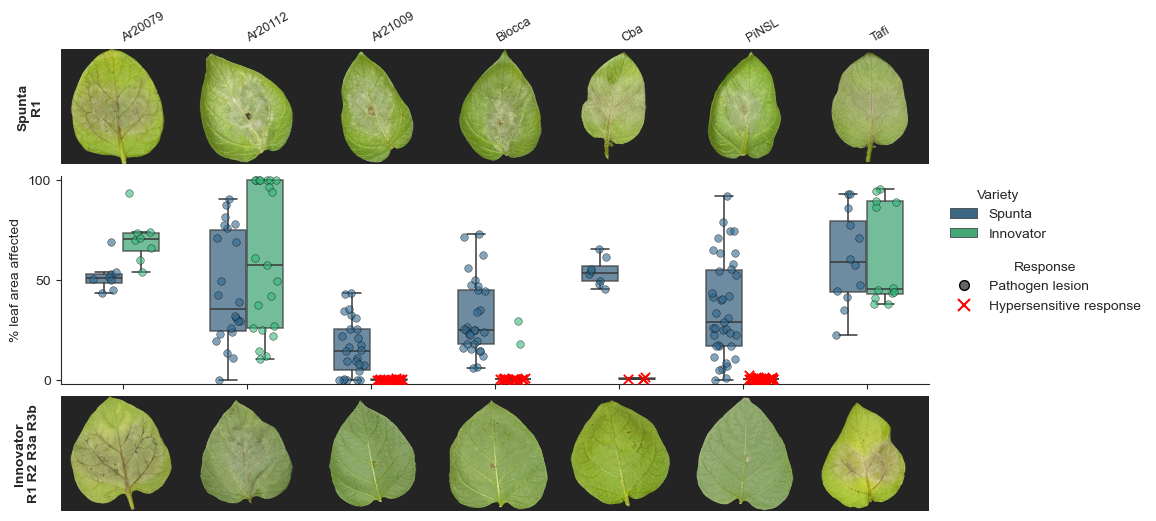

In [34]:
# ── Boxplot + photos by isolate/variety ───────────────────────────────────
df = df_leaf   # alias so the rest of the block matches the original notebook

EXCLUIR_EXP = []   # leave empty to include all experiments
exp_plot   = [e for e in experimentos if e not in EXCLUIR_EXP]
df_plot    = df[df["exp"].isin(exp_plot)]
orden_var  = [v for v in ["Spunta", "Innovator"] if v in variedades]

# Photos: one <Variety>_<isolate>.png file per combination, in this same folder
fotos = {
    "Spunta":    {a: f"inputs/Spunta_{a}.png"    for a in aislamientos},
    "Innovator": {a: f"inputs/Innovator_{a}.png" for a in aislamientos},
}

# Variety name + R genes it expresses, with a line break between them
VARIEDAD_LABELS = {
    "Spunta":    "Spunta\nR1",
    "Innovator": "Innovator\nR1 R2 R3a R3b",
}

sns.set_style("ticks")
palette = sns.color_palette("viridis", n_colors=len(orden_var))
n = len(aislamientos)

fig = plt.figure(figsize=(max(10, n * 1.6), 6))
# shorter central panel -> Y axis less dominant
gs = fig.add_gridspec(3, n, height_ratios=[1.0, 1.8, 1.0],
                      hspace=0.08, wspace=0.06)

def fondo_fila(row):
    """Black rectangle spanning the whole row, behind the photos."""
    axbg = fig.add_subplot(gs[row, :], zorder=-1)
    axbg.set_facecolor("#232423")
    axbg.set_xticks([]); axbg.set_yticks([])
    for s in axbg.spines.values():
        s.set_visible(False)
    return axbg

def fila_fotos(row, variedad, poner_titulo=False):
    for j, a in enumerate(aislamientos):
        axf = fig.add_subplot(gs[row, j])
        try:
            axf.imshow(mpimg.imread(fotos[variedad][a]))
            axf.set_facecolor("none")   # transparent photo background shows the row band
        except Exception:
            axf.set_facecolor("black")          # black placeholder if the photo is missing
        axf.set_xticks([]); axf.set_yticks([])
        for s in axf.spines.values():
            s.set_visible(False)
        if poner_titulo:
            axf.set_title(a, fontsize=9, rotation=30, ha="left")
        if j == 0:
            axf.set_ylabel(VARIEDAD_LABELS.get(variedad, variedad), rotation=90,
                           fontweight="bold", fontsize=10, labelpad=18)

# Top row: black background + Spunta photos (with isolate name on top)
fondo_fila(0)
fila_fotos(0, "Spunta", poner_titulo=True)

# Central panel: boxplot
ax = fig.add_subplot(gs[1, :])
sns.boxplot(data=df_plot, x="aislamiento", y="pct_lesionada",
            hue="variedad", order=aislamientos, hue_order=orden_var,
            palette=palette, width=0.6, fliersize=0, linewidth=1.1,
            boxprops=dict(alpha=0.75), ax=ax)

# ── Manual dodged points; red cross if value < UMBRAL ONLY in Innovator ──
UMBRAL = 5
box_width = 0.6
hue_w = box_width / len(orden_var)
jit   = hue_w * 0.35
for hi, var in enumerate(orden_var):
    offset  = -box_width / 2 + hue_w / 2 + hi * hue_w
    c_box   = palette[hi]
    sub_v   = df_plot[df_plot["variedad"] == var]
    for xi, aisl in enumerate(aislamientos):
        s = sub_v[sub_v["aislamiento"] == aisl].dropna(subset=["pct_lesionada"])
        if s.empty:
            continue
        vals = s["pct_lesionada"].values
        xs   = xi + offset + rng.uniform(-jit, jit, len(vals))
        # red crosses only in Innovator and below the threshold
        low  = (vals < UMBRAL) if var == "Innovator" else np.zeros(len(vals), dtype=bool)
        # normal points (variety color)
        ax.scatter(xs[~low], vals[~low], color=c_box, alpha=0.6,
                   s=30, edgecolor="black", linewidth=0.4, zorder=4)
        # red crosses (< UMBRAL, Innovator only)
        ax.scatter(xs[low], vals[low], color="red", marker="x",
                   s=45, linewidth=1.3, zorder=5)

ax.set_ylabel("% leaf area affected")
ax.set_xlabel("")
ax.set_xlim(-0.5, n - 0.5)
ax.set_ylim(-2, 102)
ax.set_yticks([0, 50, 100])          # fewer ticks -> less cluttered Y axis
ax.tick_params(axis="x", labelbottom=False)   # names go on the photos
sns.despine(ax=ax)

# Legend 1: Variety (the boxplot's own)
handles, hlabels = ax.get_legend_handles_labels()
k = len(orden_var)
leg1 = ax.legend(handles[:k], hlabels[:k], title="Variety",
                 frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.add_artist(leg1)   # fix it in place so the second legend doesn't remove it

# Legend 2: marker meaning
marker_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="0.4",
           markeredgecolor="black", markersize=7, label="Pathogen lesion"),
    Line2D([0], [0], marker="x", color="red", markersize=8,
           markeredgewidth=1.5, linestyle="none", label="Hypersensitive response"),
]
ax.legend(handles=marker_handles, title="Response", frameon=False,
          loc="upper left", bbox_to_anchor=(1.01, 0.65))

# Bottom row: black background + Innovator photos
fondo_fila(2)
fila_fotos(2, "Innovator")

plt.savefig("outputs/fig4/fig4_potato_boxplot.pdf", bbox_inches="tight", dpi=350)
plt.savefig("outputs/fig4/fig4_potato_boxplot.svg", bbox_inches="tight")
plt.show()


## Figure 5 — *N. benthamiana* transgenic-line infiltration assay (lesion % / HR)

Reads `WL_Nb.tsv`: one row per infiltrated leaf, with `variedad` (the transgenic
*N. benthamiana* line — empty vector control, R-gene lines, or the *Rpi-amr1*/
*Rpi-amr3*/*Rpi-blb2* lines), `aislamiento` (the *P. infestans* isolate infiltrated
onto that leaf), `healthy`/`disease` (percent leaf area, comma-decimal in the raw
file), and `HR` (whether that leaf showed a hypersensitive response, `YES`/`NO`).

Two components, following the same layout convention as Figure 4:

- A stacked boxplot of `disease` (% leaf area affected) by transgenic line, one
  row per isolate (4 isolates: PiNSL-19, Cba2, Ar20079, Tafi), so each isolate's
  distribution across all 7 transgenic lines can be read at a glance without
  needing a hue-dodge legend.
- A mean-TPM line plot (RNA-seq, isolate PiNSL infecting cv. Spunta, same source
  as the Figure 4 TPM panel) for *AVR1*, *AVR3a*, *AVR-blb2*, *AVR-amr1* and
  *AVR-amr3* — the effectors that correspond to the R-gene lines tested here.


In [35]:
# ── Config ────────────────────────────────────────────────────────────────────
WL_NB_TSV = "inputs/WL_Nb.tsv"

# Order of isolates (rows, top to bottom) and of transgenic lines
# (categories on the X axis of each row) -- both easy to change here.
# GS4 is excluded from the dataset (not part of this figure).
ISOLATE_ORDER_5  = ["PiNSL-19", "Cba2", "Ar20079", "Tafi"]
VARIEDAD_ORDER_5 = ["EV", "R1", "R3a", "blb2", "amr1", "amr3"]

# Isolates grouped by virulence phenotype on Innovator (R1/R2/R3a/R3b):
# PiNSL-19 and Cba2 share one color, Ar20079 and Tafi the other.
ISOLATE_COLOR_GROUP_5 = {"PiNSL-19": 0, "Cba2": 0, "Ar20079": 1, "Tafi": 1}

df5 = pd.read_csv(WL_NB_TSV, sep="\t", decimal=",")
df5 = df5[df5["variedad"] != "GS4"].copy()

assert set(df5["aislamiento"].unique()) == set(ISOLATE_ORDER_5)
assert set(df5["variedad"].unique()) == set(VARIEDAD_ORDER_5)

print(f"Rows loaded (excluding GS4): {len(df5):,}")
df5.groupby(["aislamiento", "variedad"]).size().unstack()


Rows loaded (excluding GS4): 365


variedad,EV,R1,R3a,amr1,amr3,blb2
aislamiento,,,,,,
Ar20079,18,15,16,16,16,19
Cba2,14,14,14,14,14,14
PiNSL-19,18,10,12,15,19,20
Tafi,14,15,15,16,16,11


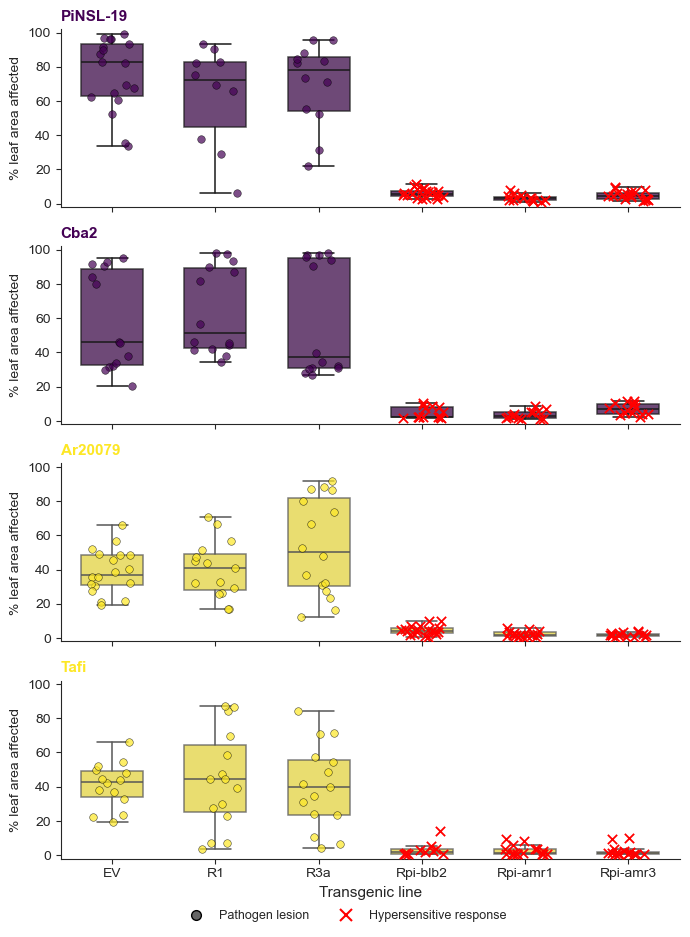

In [36]:
# ── Boxplot of % leaf area affected by transgenic line, stacked by isolate ─
# One color per row (isolate), grouped by virulence phenotype on Innovator
# (ISOLATE_COLOR_GROUP_5: PiNSL-19/Cba2 vs. Ar20079/Tafi) -- unlike
# Figure 4, here color does NOT encode the variety/transgenic line (that's
# on the X axis of each row), it groups isolates by phenotype instead.
rng5 = np.random.default_rng(7)
# Extreme ends of the viridis colormap (violet -> yellow), same convention as
# Figure 4's boxplot -- sns.color_palette(..., n_colors=2) only returns muted
# mid-range colors, not the true endpoints.
_viridis5 = matplotlib.colormaps["viridis"]
ROW_PALETTE_5 = [_viridis5(0.0), _viridis5(1.0)]
JIT_5 = 0.6 * 0.35

# Labels to show on the X axis (R-gene lines carry the "Rpi-" prefix,
# same as in the Nbs.png photo; EV/R1/R3a stay as-is)
VARIEDAD_LABELS_5 = {"blb2": "Rpi-blb2", "amr1": "Rpi-amr1", "amr3": "Rpi-amr3"}
xticklabels_5 = [VARIEDAD_LABELS_5.get(v, v) for v in VARIEDAD_ORDER_5]

sns.set_style("ticks")
fig, axes = plt.subplots(nrows=len(ISOLATE_ORDER_5), ncols=1,
                          figsize=(7, 2.3 * len(ISOLATE_ORDER_5)), sharex=True)

for i, iso in enumerate(ISOLATE_ORDER_5):
    ax = axes[i]
    row_color = ROW_PALETTE_5[ISOLATE_COLOR_GROUP_5[iso]]
    sub_iso = df5[df5["aislamiento"] == iso]

    sns.boxplot(data=sub_iso, x="variedad", y="disease", order=VARIEDAD_ORDER_5,
                color=row_color, width=0.6, fliersize=0, linewidth=1.1,
                boxprops=dict(alpha=0.75), ax=ax)

    for vi, var in enumerate(VARIEDAD_ORDER_5):
        s = sub_iso[sub_iso["variedad"] == var]
        if s.empty:
            continue
        xs = vi + rng5.uniform(-JIT_5, JIT_5, len(s))
        hr_yes = (s["HR"] == "YES").values
        vals = s["disease"].values
        # normal points (no HR)
        ax.scatter(xs[~hr_yes], vals[~hr_yes], color=row_color, alpha=0.7, s=30,
                   edgecolor="black", linewidth=0.4, zorder=4)
        # red crosses (HR = YES)
        ax.scatter(xs[hr_yes], vals[hr_yes], color="red", marker="x", s=45,
                   linewidth=1.3, zorder=5)

    ax.set_title(iso, loc="left", fontsize=11, fontweight="bold", color=row_color)
    ax.set_ylabel("% leaf area affected", fontsize=10)
    ax.set_xlabel("")
    ax.set_xticks(range(len(VARIEDAD_ORDER_5)))
    ax.set_xticklabels(xticklabels_5)
    ax.set_ylim(-2, 102)
    sns.despine(ax=ax)
    if i < len(ISOLATE_ORDER_5) - 1:
        ax.tick_params(axis="x", labelbottom=False)

axes[-1].set_xlabel("Transgenic line", fontsize=11)

marker_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="0.4",
           markeredgecolor="black", markersize=7, label="Pathogen lesion"),
    Line2D([0], [0], marker="x", color="red", markersize=8,
           markeredgewidth=1.5, linestyle="none", label="Hypersensitive response"),
]
fig.legend(handles=marker_handles, loc="lower center", bbox_to_anchor=(0.5, -0.02),
           ncol=2, frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig("outputs/fig5/fig5_lesion_boxplot.pdf", bbox_inches="tight", dpi=350)
plt.savefig("outputs/fig5/fig5_lesion_boxplot.svg", bbox_inches="tight")
plt.show()


## AVR1 / AVR3a / AVR-blb2 / AVR-amr1 / AVR-amr3 — mean TPM across infection timepoints

Same source as the Figure 4 TPM panel (`TPM_efectores.tsv`, isolate PiNSL
infecting cv. Spunta), plotted here as mean log2(TPM + 1) (± 1 SD in log2 space)
across in vitro mycelium and 24/48/72 hpi, one line per gene, for the five
effectors that correspond to the transgenic lines tested in the *N. benthamiana*
assay above (*AVR1*↔R1, *AVR3a*↔R3a, *AVR-blb2*↔blb2, *AVR-amr1*↔amr1,
*AVR-amr3*↔amr3). Each replicate is log2(TPM + 1)-transformed individually
before averaging (pseudocount = 1, so *AVR1*'s TPM = 0 maps to log2(1) = 0
rather than being undefined).


In [37]:
# ── Config ────────────────────────────────────────────────────────────────────
TPM_TSV_PATH_5 = "inputs/TPM_efectores.tsv"
TPM_MATRIX_5   = "inputs/TPM_matrix.tsv"   # genome-wide matrix (18179 genes) -- needed for
                                    # PITG_04090, which isn't in TPM_efectores.tsv
GENE_NAMES_5   = ["AVR1", "AVR3a", "AVR-amr1", "AVR-amr3"]
TIME_ORDER_5   = ["Myc", "24", "48", "72"]

# AVR-blb2 (PITG_04090) per tabla_efectores.xlsx ("Avrblb2 family,
# secreted RxLR effector peptide, putative") -- plotted here as the sole
# representative of the AVR-blb2 family; full paralog-level detail (all 19
# members) is shown separately in the circular tree (Figure 5D).
AVRBLB2_PARALOGS_5 = ["PITG_04090"]

# --- Load and parse the "Gene" column (same file as the Figure 4 panel) ---
tpm_raw5 = pd.read_csv(TPM_TSV_PATH_5, sep="\t")
gene_parts5 = tpm_raw5["Gene"].str.split(expand=True)
tpm5 = pd.concat([
    gene_parts5[[0, 1]].rename(columns={0: "PITG", 1: "gene_name"}),
    tpm_raw5[["Time", "Experiment", "TPM"]],
], axis=1)

tpm5["Time"] = tpm5["Time"].astype(str).str.strip()
tpm5 = tpm5[tpm5["Time"].isin(TIME_ORDER_5)].copy()
tpm5["Time"] = pd.Categorical(tpm5["Time"], categories=TIME_ORDER_5, ordered=True)

sub5 = tpm5[tpm5["gene_name"].isin(GENE_NAMES_5)].copy()

def make_label5(row):
    return f'{row["gene_name"]} ({row["PITG"]})'
sub5["label"] = sub5.apply(make_label5, axis=1)

# --- Add the AVR-blb2 paralog from the genome-wide matrix (wide format:
# one column per Experiment+timepoint combination, e.g. "B3" = Experiment B,
# 24 hpi; "CtrlN" = mycelium) ---
def parse_col_5(col):
    if col.startswith("Ctrl"):
        return "Myc", "Myc"
    time_map = {"3": "24", "4": "48", "5": "72"}
    return col[0], time_map[col[1]]

tmat5 = pd.read_csv(TPM_MATRIX_5, sep="\t")
extra5 = tmat5[tmat5["gene_id"].isin(AVRBLB2_PARALOGS_5)]

extra_rows = []
for _, r in extra5.iterrows():
    for col in tmat5.columns[1:]:
        exp, time = parse_col_5(col)
        extra_rows.append({
            "PITG": r["gene_id"], "gene_name": "AVR-blb2",
            "Time": time, "Experiment": exp, "TPM": r[col],
            "label": f'AVR-blb2 ({r["gene_id"]})',
        })
extra_long5 = pd.DataFrame(extra_rows)
extra_long5["Time"] = pd.Categorical(extra_long5["Time"], categories=TIME_ORDER_5, ordered=True)

sub5 = pd.concat([sub5, extra_long5], ignore_index=True)

print("Loci included:")
print(sub5[["gene_name", "PITG", "label"]].drop_duplicates().to_string(index=False))


Loci included:
gene_name       PITG                 label
 AVR-amr1 PITG_07569 AVR-amr1 (PITG_07569)
    AVR3a PITG_14371    AVR3a (PITG_14371)
 AVR-amr3 PITG_21190 AVR-amr3 (PITG_21190)
     AVR1 PITG_16663     AVR1 (PITG_16663)
 AVR-blb2 PITG_04090 AVR-blb2 (PITG_04090)


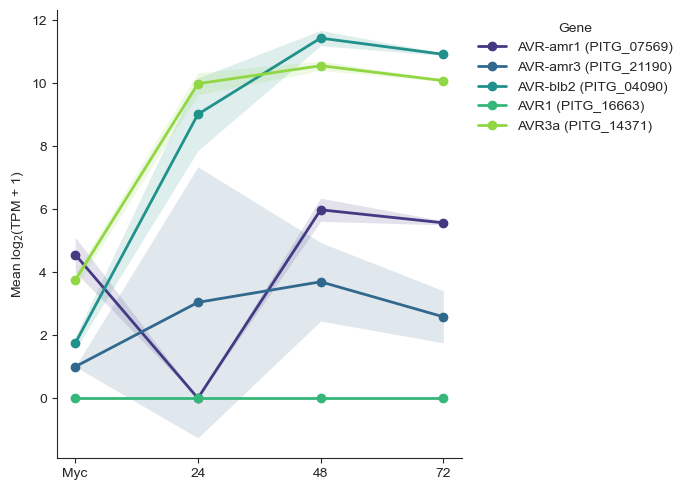

In [38]:
# ── Mean log2(TPM + 1) per gene x timepoint (across replicates/experiments) ─────
# Each individual replicate is transformed with log2(TPM + 1) (pseudocount = 1,
# to be able to include AVR1, which has TPM = 0) and ONLY THEN averaged -- the
# raw TPM mean is not transformed directly, so that the spread (shaded band)
# correctly reflects the dispersion in log2 scale.
sub5["log2_TPM"] = np.log2(sub5["TPM"] + 1)

mean_tpm5 = (
    sub5.groupby(["label", "Time"], observed=True, as_index=False)
        .agg(mean_log2TPM=("log2_TPM", "mean"), sd_log2TPM=("log2_TPM", "std"), n=("TPM", "size"))
)
mean_tpm5["sd_log2TPM"] = mean_tpm5["sd_log2TPM"].fillna(0.0)

tpm_labels5 = sorted(sub5["label"].unique())

# --- Color: one color per gene/label -- no special-casing needed now that
# AVR-blb2 is represented by a single paralog (PITG_04090). ---
palette_tpm5 = dict(zip(tpm_labels5, sns.color_palette("viridis", n_colors=len(tpm_labels5))))

sns.set_style("ticks")
fig, ax = plt.subplots(figsize=(7, 5))

for lbl in tpm_labels5:
    d = mean_tpm5[mean_tpm5["label"] == lbl].set_index("Time").reindex(TIME_ORDER_5)
    x = np.arange(len(TIME_ORDER_5))
    y = d["mean_log2TPM"]
    ax.plot(x, y, marker="o", color=palette_tpm5[lbl], linewidth=2,
            markersize=6, label=lbl)
    ax.fill_between(x, y - d["sd_log2TPM"], y + d["sd_log2TPM"],
                     color=palette_tpm5[lbl], alpha=0.15, linewidth=0)

ax.set_xticks(np.arange(len(TIME_ORDER_5)))
ax.set_xticklabels(TIME_ORDER_5)
ax.set_xlabel("")
ax.set_ylabel("Mean log$_2$(TPM + 1)")
sns.despine(ax=ax)

ax.legend(title="Gene", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.savefig("outputs/fig5/AVR1_AVR3a_blb2_amr1_amr3_TPM.png", dpi=400, bbox_inches="tight", format="png")
plt.show()
